# EXP-032 — deployable DenseNet121 + YOLO26s pipeline

Run top to bottom in a fresh Colab GPU runtime. `RUN_PART_A` uses frozen EXP-029 probabilities; `RUN_PART_B` trains five DenseNet seeds and exports the deployable pipeline. Part A and Part B produce separate tables. Holdout 09 is a **descriptive audit, not a blind benchmark**. No YOLO retraining, no split change, and no Holdout-driven tuning.

The detector's YOLO Test split (412 images) has not been scored by the detector training experiment and is used for localization. The EXP-029 Split 13 Test/Holdout are evaluated only after the clean-Validation fusion config is frozen. `F2` is explicitly post hoc. The exploratory stacker feature set was exposed to Test/Holdout before this notebook; its prior Holdout 97.62% (3 errors, all anthracnose→red_rust) is disclosed, not a target or claim.

Set `EXP032_DRY_RUN=1` only for the synthetic test; its outputs cannot be reported as real results.


In [ ]:
# EXP-032 configuration and imports
import base64, csv, gc, hashlib, io, json, os, platform, shutil, stat, subprocess, sys, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageOps
from scipy.stats import norm
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, log_loss, precision_recall_fscore_support)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib
import importlib.util

LEGACY_EXPERIMENT_ID = "EXP-DENSENET121-YOLO-PIPELINE-032"
EXPERIMENT_ID = "EXP-DENSENET121-YOLO-PIPELINE-032-R1"
SEEDS = [42, 123, 2026, 3407, 7777]
CLASSES = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
DETECTOR_CLASSES = ["anthracnose", "leaf_miner", "red_rust"]
CLASS_NAMES = CLASSES
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}
BASELINE_EXPERIMENT_ID = "EXP-DENSENET121-TRANSFER-5SEEDS-029-256px-9c23ac05"
DATASET_ARCHIVE_NAME = "CashewData_Split (13).zip"
DATASET_ARCHIVE_FILE_ID = "1HUE5ObO1vW0mP2QjgsdObMuW4RVPzNk7"
DATASET_ARCHIVE_EXPECTED_BYTES = 1470301553
DATASET_ARCHIVE_SHA256 = "e1647b72e10af04275dc760545f4ef17c9f44343ae119495b89ba1e3cd954e04"
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (9).zip"
REAL_HOLDOUT_ARCHIVE_FILE_ID = "1QW2JYx8K6zkTs9y34f39OTBlxUOjWosZ"
REAL_HOLDOUT_EXPECTED_BYTES = 370947341
YOLO_DATASET_ARCHIVE_NAME = "CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip"
YOLO_DATASET_FILE_ID = "1cRQ-kR1lsEvyqvs0Qn8rhUS4mvdi4nD2"
YOLO_DATASET_EXPECTED_BYTES = 246419660
YOLO_DATASET_FINGERPRINT = "1acc0edcf7f736f9754e4977b61133a7ec5582b44d8cf3eef27208f49a202add"
DRIVE_TARGET_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"
DETECTOR_NAME = "EXP-Y26S-NEG-V03-001-CLASS-WEIGHTED"
DETECTOR_FULL_ZIP = "EXP-Y26S-NEG-V03-001_FULL.zip"
DETECTOR_FULL_ZIP_URL = "https://raw.githubusercontent.com/klongnguyen/KLTN_Cashew_Leaf_Disease_Classification/ac1efe16319052b6f08a3c41b4ec361bbbb19e2f/training_results/negative_evaluation/EXP-Y26S-NEG-V03-001_FULL.zip"
DETECTOR_FULL_ZIP_EXPECTED_BYTES = 51515079
DETECTOR_FULL_ZIP_SHA256 = "e1d3cc42afd356aaf3431486cb6f518344582e836872a36bfb651195deaf542d"
DETECTOR_WEIGHTS_MEMBER = "train/weights/best.pt"
DETECTOR_WEIGHTS_SHA256 = "66717b5523ba394443495378a326da26f0d24e98a331f98480f79d9d6fa18166"
DATASET_ARCHIVE_OVERRIDE = None
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None
YOLO_DATASET_OVERRIDE = None
DETECTOR_WEIGHTS_OVERRIDE = None
RUN_PART_A, RUN_PART_B = True, True
UPLOAD_RESULT_ZIPS_TO_DRIVE = True
USE_EXTRA_BLIND_SET = False
EXTRA_BLIND_DRIVE_FOLDER_ID = ""  # Required only when USE_EXTRA_BLIND_SET is True.
DRY_RUN = os.environ.get("EXP032_DRY_RUN") == "1"  # Synthetic fixture only; never an EXP-032 result.
if USE_EXTRA_BLIND_SET:
    assert EXTRA_BLIND_DRIVE_FOLDER_ID.strip()
if DRY_RUN:
    RUN_PART_A, RUN_PART_B, UPLOAD_RESULT_ZIPS_TO_DRIVE = True, True, False
else:
    for package,module in (("google-api-python-client","googleapiclient"),
                           ("google-auth","google.auth")):
        try: found=importlib.util.find_spec(module)
        except ModuleNotFoundError: found=None
        if found is None: subprocess.check_call([sys.executable,"-m","pip","install",package])
PROJECT_ROOT = Path("/content") if Path("/content").is_dir() else Path.cwd()
OUT_DIR = PROJECT_ROOT / "training_results" / "current_dataset" / (EXPERIMENT_ID + ("-DRYRUN" if DRY_RUN else ""))
AGGREGATE = OUT_DIR / "aggregate"
AGGREGATE.mkdir(parents=True, exist_ok=True)
STAGE_ROOT = PROJECT_ROOT / "exp032_inputs"
YOLO_INFERENCE_CONF, YOLO_INFERENCE_IOU, YOLO_IMGSZ = 0.05, 0.7, 640
TAU = 0.60
IMG_SIZE, BATCH_SIZE = 256, 16
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE2_LR, STAGE2_EPOCHS = 1e-5, 30
WEIGHT_DECAY, HEAD_DROPOUT = 1e-4, 0.40
REAL_OVERSAMPLE_FACTOR, SELECTION_PRIMARY_METRIC = 1, "val_loss"
if DRY_RUN:
    SEEDS, STAGE1_EPOCHS, STAGE2_EPOCHS = [42, 123], 1, 1

def file_md5(path):
    digest = hashlib.md5()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, default=str), encoding="utf-8")

def unique_keys(frame, label):
    if frame["evidence_key"].duplicated().any():
        raise ValueError(f"{label}: duplicate split/class/filename keys")
    if any(len(str(key).split("/")) != 3 for key in frame["evidence_key"]):
        raise ValueError(f"{label}: keys must be split/class/filename")

def checked_join(left, right, label):
    unique_keys(left, label + " left")
    unique_keys(right, label + " right")
    a, b = set(left.evidence_key), set(right.evidence_key)
    if a != b:
        raise ValueError(f"{label}: key mismatch; missing={sorted(a-b)[:3]} extra={sorted(b-a)[:3]}")
    return left.merge(right, on="evidence_key", validate="one_to_one")

print("EXP-032", platform.python_version(), "dry_run", DRY_RUN,
      "Part A", RUN_PART_A, "Part B", RUN_PART_B)
print("Detector Val mAP50=0.7163 mAP50-95=0.3981; YOLO train/val/test=3497/951/412 (negatives 621/58/0).")
print("Detector config FINAL_TEST_EVALUATION=false; YOLO Test is the clean localization split.")


In [ ]:
# 01a. FROZEN EXP-029 PREDICTION BUNDLE
# The 15 real EXP-029 prediction CSVs, extracted from its ANALYSIS ZIP.
# Source ANALYSIS ZIP SHA256: 223298083582e13b9312a8f17c9e1e1282e68af45ce33d23db6e2f448639a86e
EXP029_PREDICTION_BUNDLE_SHA256 = '5b091e335e3194dfaeacfa9a2891d6001bb929b8eb1b432e64ecd8a01634952d'
EXP029_PREDICTION_BUNDLE_B64 = '...'


In [ ]:
# Stage pinned inputs. Source helpers copied from EXP-031 by header.
def archive_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

def source_archive(file_id, name, expected_bytes, override):
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'Archive override missing: {path}')
    else:
        path = STAGE_ROOT / 'archives' / name
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.is_file() or path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
            if not file_id:
                raise FileNotFoundError(f'{name}: set a Drive file ID or archive override')
            import google.auth
            from googleapiclient.discovery import build
            from googleapiclient.http import MediaIoBaseDownload
            if Path('/content').is_dir():
                from google.colab import auth
                auth.authenticate_user()
            credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
            service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
            meta = service.files().get(fileId=file_id, fields='id,name,size,md5Checksum',
                                       supportsAllDrives=True).execute()
            if meta['name'] != name or int(meta['size']) != expected_bytes:
                raise ValueError(f'Drive source differs from expected {name}: {meta}')
            partial = path.with_suffix(path.suffix + '.part')
            request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
            with partial.open('wb') as stream:
                downloader = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
                done = False
                while not done:
                    progress, done = downloader.next_chunk(num_retries=3)
                    if progress:
                        print(name, f'{progress.progress():.0%}')
            if partial.stat().st_size != expected_bytes or not zipfile.is_zipfile(partial):
                raise RuntimeError(f'Incomplete archive download: {name}')
            if meta.get('md5Checksum'):
                digest = hashlib.md5()
                with partial.open('rb') as stream:
                    for block in iter(lambda: stream.read(8 << 20), b''):
                        digest.update(block)
                if digest.hexdigest() != meta['md5Checksum']:
                    raise RuntimeError(f'Drive MD5 mismatch: {name}')
            partial.replace(path)
    if path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
        raise ValueError(f'Archive size/type mismatch: {path}')
    return path

def extract_verified(archive_path, destination):
    archive_path, destination = Path(archive_path), Path(destination)
    checksum = archive_sha256(archive_path)
    marker = destination / '.archive_sha256'
    if destination.is_dir():
        if not marker.is_file() or marker.read_text(encoding='utf-8').strip() != checksum:
            raise RuntimeError(f'Unverified/incomplete extraction: {destination}')
        return destination
    staging = destination.with_name(destination.name + '_staging')
    if staging.exists():
        raise RuntimeError(f'Incomplete staging directory: {staging}')
    staging.mkdir(parents=True)
    with zipfile.ZipFile(archive_path) as archive:
        resolved_root = staging.resolve()
        for member in archive.infolist():
            target = (staging / member.filename.replace('\\', '/')).resolve()
            if (stat.S_ISLNK(member.external_attr >> 16) or
                    not target.is_relative_to(resolved_root)):
                raise ValueError(f'Unsafe archive member: {member.filename}')
        archive.extractall(staging)
    (staging / '.archive_sha256').write_text(checksum + '\n', encoding='utf-8')
    staging.rename(destination)
    return destination


def ensure_detector_weights(project_root, override, archive_name, archive_url,
                            archive_bytes, archive_sha256, weights_member,
                            weights_sha256):
    """Return a verified best.pt, reusing local files before downloading."""
    project_root = Path(project_root)
    weights = Path(override).expanduser() if override else project_root / 'detector' / 'best.pt'
    if weights.is_file():
        found = file_sha256(weights)
        if found != weights_sha256:
            raise ValueError(f'YOLO best.pt SHA256 mismatch: {found}')
        print('Verified YOLO best.pt:', weights, found[:16])
        return weights
    if override:
        raise FileNotFoundError(f'DETECTOR_WEIGHTS_OVERRIDE does not exist: {weights}')

    candidates = sorted(project_root.rglob(archive_name))
    if len(candidates) > 1:
        raise RuntimeError(f'Multiple YOLO FULL ZIPs found; select one explicitly: {candidates}')
    if candidates:
        archive_path = candidates[0]
        source = 'local archive'
    else:
        import urllib.request
        archive_path = project_root / 'detector' / archive_name
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        partial = archive_path.with_suffix('.zip.part')
        request = urllib.request.Request(archive_url,
                                         headers={'User-Agent': 'EXP-031-checkpoint-provenance'})
        try:
            with urllib.request.urlopen(request, timeout=60) as response, partial.open('wb') as target:
                while True:
                    block = response.read(8 << 20)
                    if not block:
                        break
                    target.write(block)
            if partial.stat().st_size != archive_bytes:
                raise ValueError(f'Incomplete YOLO FULL ZIP: {partial.stat().st_size} bytes')
            actual = file_sha256(partial)
            if actual != archive_sha256:
                raise ValueError(f'YOLO FULL ZIP SHA256 mismatch: {actual}')
            partial.replace(archive_path)
        except Exception as exc:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                'Could not fetch the pinned YOLO FULL ZIP from GitHub. '
                'Place the verified ZIP on the runtime or set DETECTOR_WEIGHTS_OVERRIDE.'
            ) from exc
        source = 'pinned GitHub commit'

    if archive_path.stat().st_size != archive_bytes:
        raise ValueError(f'YOLO FULL ZIP size mismatch: {archive_path}')
    found_zip = file_sha256(archive_path)
    if found_zip != archive_sha256:
        raise ValueError(f'YOLO FULL ZIP SHA256 mismatch: {found_zip}')
    with zipfile.ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise ValueError(f'Corrupt YOLO FULL ZIP: {archive_path}')
        checkpoint = archive.read(weights_member)
    found_weights = hashlib.sha256(checkpoint).hexdigest()
    if found_weights != weights_sha256:
        raise ValueError(f'YOLO best.pt SHA256 mismatch: {found_weights}')
    weights.parent.mkdir(parents=True, exist_ok=True)
    temp_weights = weights.with_suffix('.pt.part')
    temp_weights.write_bytes(checkpoint)
    temp_weights.replace(weights)
    print('Verified YOLO best.pt from', source, '|', archive_path,
          '| SHA256', found_weights[:16])
    return weights


import urllib.request
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_files(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)

def dataset_root(extracted, kind):
    candidates = [Path(extracted), *[p for p in Path(extracted).rglob("*") if p.is_dir()]]
    if kind == "split13":
        matches = [p for p in candidates if (p / "train").is_dir() and (p / "val").is_dir() and (p / "test").is_dir()]
    elif kind == "holdout09":
        matches = [p for p in candidates if all((p / c).is_dir() for c in CLASSES[:4]) and
                   len([q for q in p.iterdir() if q.is_dir()]) == 4]
    elif kind == "yolo":
        matches = [p for p in candidates if all((p / "images" / s).is_dir() and (p / "labels" / s).is_dir()
                   for s in ("train", "val", "test"))]
    else:
        raise ValueError(kind)
    if len(matches) != 1:
        raise RuntimeError(f"{kind}: expected one root, found {matches}")
    return matches[0]

def synthetic_fixture():
    import tempfile
    root = STAGE_ROOT / "synthetic_exp032"
    if root.exists():
        shutil.rmtree(root)
    split_root, hold_root, yolo_root = root / "split13", root / "holdout09", root / "yolo"
    rng = np.random.default_rng(32)
    for split, classes, per_class in (("train", CLASSES, 2), ("val", CLASSES, 2),
                                      ("test", CLASSES, 2), ("holdout", CLASSES[:4], 2)):
        for ci, cls in enumerate(classes):
            for i in range(per_class):
                target = (hold_root if split == "holdout" else split_root / split) / cls / f"{cls}_{split}_{i}.png"
                target.parent.mkdir(parents=True, exist_ok=True)
                pixels = rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)
                pixels[:, :, ci % 3] = np.clip(pixels[:, :, ci % 3].astype(int) + 45, 0, 255)
                Image.fromarray(pixels.astype(np.uint8)).save(target)
    for split, count in (("train", 10), ("val", 6), ("test", 6)):
        for i in range(count):
            image = yolo_root / "images" / split / f"{'real_' if i % 2 else ''}{split}_{i}.png"
            label = yolo_root / "labels" / split / (image.stem + ".txt")
            image.parent.mkdir(parents=True, exist_ok=True)
            label.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)).save(image)
            label.write_text(f"{i % 3} 0.5 0.5 0.4 0.4\n", encoding="utf-8")
    return split_root, hold_root, yolo_root

if DRY_RUN:
    SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT = synthetic_fixture()
    DETECTOR_WEIGHTS_PATH = None
    print("Synthetic fixture:", SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT)
else:
    # EXP-031 embedded 15-table bundle. Extract Validation first; defer Test/Holdout.
    EXP029_BUNDLE_BYTES = base64.b64decode(EXP029_PREDICTION_BUNDLE_B64, validate=True)
    assert hashlib.sha256(EXP029_BUNDLE_BYTES).hexdigest() == EXP029_PREDICTION_BUNDLE_SHA256
    target = STAGE_ROOT / "exp029"
    with zipfile.ZipFile(io.BytesIO(EXP029_BUNDLE_BYTES)) as archive:
        EXP029_MANIFEST = json.loads(archive.read("manifest.json"))
    ANALYSIS_ROOT = target / BASELINE_EXPERIMENT_ID
    def ensure_exp029_split(split):
        if split in ("test","holdout") and not (AGGREGATE/"frozen_config_partA.json").is_file():
            raise RuntimeError("Freeze Part A on clean Validation before accessing Test/Holdout predictions")
        fragment = ("/real_holdout/" if split=="holdout" else f"/{split}/")
        with zipfile.ZipFile(io.BytesIO(EXP029_BUNDLE_BYTES)) as archive:
            names=[name for name in EXP029_MANIFEST["members"] if fragment in name]
            assert len(names)==len(SEEDS)
            for name in names:
                expected=EXP029_MANIFEST["members"][name]
                dest=target/name
                assert dest.resolve().is_relative_to(target.resolve())
                dest.parent.mkdir(parents=True,exist_ok=True)
                if not dest.is_file() or file_sha256(dest)!=expected:
                    data=archive.read(name)
                    assert hashlib.sha256(data).hexdigest()==expected
                    dest.write_bytes(data)
    ensure_exp029_split("validation")
    split_archive = source_archive(DATASET_ARCHIVE_FILE_ID, DATASET_ARCHIVE_NAME,
                                   DATASET_ARCHIVE_EXPECTED_BYTES, DATASET_ARCHIVE_OVERRIDE)
    assert file_sha256(split_archive) == DATASET_ARCHIVE_SHA256
    hold_archive = source_archive(REAL_HOLDOUT_ARCHIVE_FILE_ID, REAL_HOLDOUT_ARCHIVE_NAME,
                                  REAL_HOLDOUT_EXPECTED_BYTES, REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    yolo_archive = source_archive(YOLO_DATASET_FILE_ID, YOLO_DATASET_ARCHIVE_NAME,
                                  YOLO_DATASET_EXPECTED_BYTES, YOLO_DATASET_OVERRIDE)
    SPLIT13_ROOT = dataset_root(extract_verified(split_archive, STAGE_ROOT / "split13"), "split13")
    HOLDOUT_ROOT = dataset_root(extract_verified(hold_archive, STAGE_ROOT / "holdout09"), "holdout09")
    YOLO_ROOT = dataset_root(extract_verified(yolo_archive, STAGE_ROOT / "yolo"), "yolo")
    DETECTOR_WEIGHTS_PATH = ensure_detector_weights(
        PROJECT_ROOT, DETECTOR_WEIGHTS_OVERRIDE, DETECTOR_FULL_ZIP,
        DETECTOR_FULL_ZIP_URL, DETECTOR_FULL_ZIP_EXPECTED_BYTES,
        DETECTOR_FULL_ZIP_SHA256, DETECTOR_WEIGHTS_MEMBER, DETECTOR_WEIGHTS_SHA256)

SPLIT_DIRS = {"train": SPLIT13_ROOT / "train", "validation": SPLIT13_ROOT / "val",
              "test": SPLIT13_ROOT / "test", "holdout": HOLDOUT_ROOT}
YOLO_DIRS = {split: YOLO_ROOT / "images" / split for split in ("train", "val", "test")}
YOLO_LABEL_DIRS = {split: YOLO_ROOT / "labels" / split for split in ("train", "val", "test")}
if not DRY_RUN:
    assert [len(image_files(SPLIT_DIRS[s])) for s in ("train", "validation", "test", "holdout")] == [4972,1452,685,126]
    assert [len(image_files(YOLO_DIRS[s])) for s in ("train", "val", "test")] == [3497,951,412]

def inventory(split, root):
    rows = [{"evidence_key": f"{split}/{('_detector/' if split.startswith('yolo_') else '')}{p.relative_to(root).as_posix()}",
             "path": str(p), "true_label": p.parent.name} for p in image_files(root)]
    frame = pd.DataFrame(rows)
    unique_keys(frame, split)
    return frame

INVENTORY = {s: inventory(s, path) for s, path in SPLIT_DIRS.items()}
YOLO_INVENTORY = {s: inventory("yolo_" + s, path) for s, path in YOLO_DIRS.items()}
print("Classifier images", {s: len(f) for s,f in INVENTORY.items()})
print("YOLO images", {s: len(f) for s,f in YOLO_INVENTORY.items()})


In [ ]:
# Frozen EXP-029 probabilities and pixel/pHash leakage audit.
PROB_COLUMNS = [f"prob_{name}" for name in CLASSES]

def load_exp029_split(split):
    if DRY_RUN:
        rng = np.random.default_rng(29032)
        frames = []
        for seed in SEEDS:
            rows = []
            for row in INVENTORY[split].itertuples():
                p = rng.dirichlet(np.ones(len(CLASSES)) * .1)
                p[CLASS_INDEX[row.true_label]] += 3.0
                p /= p.sum()
                rows.append({"evidence_key": row.evidence_key, "true_label": row.true_label,
                             **dict(zip(PROB_COLUMNS, p))})
            frame = pd.DataFrame(rows)
            frame["seed"] = seed
            frames.append(frame)
    else:
        ensure_exp029_split(split)
        frames = []
        for seed in SEEDS:
            path = (ANALYSIS_ROOT / "real_holdout" / f"seed_{seed}" / "predictions.csv" if split == "holdout"
                    else ANALYSIS_ROOT / f"seed_{seed}" / split / "predictions.csv")
            source = pd.read_csv(path)
            relcol = "relative_path" if "relative_path" in source else "filename"
            key = source[relcol].astype(str).map(lambda p: "/".join(Path(p).parts[-2:]))
            labels = source["class"] if "class" in source else source["true_label"]
            frame = pd.DataFrame({"evidence_key": split + "/" + key, "true_label": labels, "seed": seed})
            for cls in CLASSES:
                old = f"probability_{cls}" if f"probability_{cls}" in source else f"prob_{cls}"
                frame[f"prob_{cls}"] = source[old].astype(float)
            frames.append(frame)
    expected = set(INVENTORY[split].evidence_key)
    for frame in frames:
        unique_keys(frame, f"EXP-029 {split}")
        assert set(frame.evidence_key) == expected
        assert (frame.evidence_key.str.split("/").str[1] == frame.true_label).all()
        assert np.allclose(frame[PROB_COLUMNS].sum(axis=1), 1, atol=1e-4)
    ensemble = frames[0][["evidence_key", "true_label"]].copy()
    for cls in CLASSES:
        ensemble[f"prob_{cls}"] = np.mean([f.set_index("evidence_key").loc[ensemble.evidence_key, f"prob_{cls}"].to_numpy()
                                                 for f in frames], axis=0)
    seed_dir = OUT_DIR / "partA_seed_predictions"
    seed_dir.mkdir(exist_ok=True)
    for seed, frame in zip(SEEDS, frames):
        frame.to_csv(seed_dir / f"{split}_seed_{seed}.csv", index=False)
    return ensemble

def pixel_sha256(path):
    with Image.open(path) as handle:
        rgb = ImageOps.exif_transpose(handle).convert("RGB")
        digest = hashlib.sha256(f"{rgb.width}x{rgb.height}:".encode())
        digest.update(rgb.tobytes())
        return digest.hexdigest()

def phash64(path):
    # EXP-031's FFT pHash, with the DC bit restored to form a full 64-bit word.
    with Image.open(path) as handle:
        gray = ImageOps.exif_transpose(handle).convert("L").resize((32,32), Image.BILINEAR)
    low = np.fft.fft2(np.asarray(gray, dtype=np.float32))[:8,:8].real.flatten()
    bits = low[1:] > np.median(low[1:])
    return (1 << 63) | int("".join("1" if bit else "0" for bit in bits), 2)

def fingerprint(frame):
    out = frame[["evidence_key", "path"]].copy()
    out["pixel_sha256"] = [pixel_sha256(p) for p in out.path]
    out["phash64"] = [phash64(p) for p in out.path]
    unique_keys(out, "fingerprint")
    return out

train_fp = fingerprint(YOLO_INVENTORY["train"])
target_fp = {s: fingerprint(INVENTORY[s]) for s in ("validation", "test", "holdout")}
target_fp["yolo_test"] = fingerprint(YOLO_INVENTORY["test"])
train_by_pixel = defaultdict(list)
for row in train_fp.itertuples():
    train_by_pixel[row.pixel_sha256].append(row.evidence_key)
train_hashes = [(r.evidence_key, int(r.phash64)) for r in train_fp.itertuples()]
AUDIT, NEAR_KEYS = {}, {}
for split, frame in target_fp.items():
    pairs, exact, near_keys = [], [], set()
    for row in frame.itertuples():
        matches = train_by_pixel.get(row.pixel_sha256, [])
        exact.extend({"target": row.evidence_key, "train": key} for key in matches)
        for key, value in train_hashes:
            distance = (int(row.phash64) ^ value).bit_count()
            if distance <= 4:
                pairs.append({"target": row.evidence_key, "train": key, "hamming": distance})
                near_keys.add(row.evidence_key)
    pd.DataFrame(pairs, columns=["target","train","hamming"]).to_csv(AGGREGATE / f"leak_{split}_near.csv", index=False)
    AUDIT[split] = {"exact_pairs": len(exact), "near_pairs": len(pairs),
                    "near_images": len(near_keys), "exact_keys": sorted({r["target"] for r in exact})}
    NEAR_KEYS[split] = near_keys
    print(split, AUDIT[split])
    if split in ("test", "holdout") and exact:
        raise RuntimeError(f"Exact YOLO-train leakage in {split}")
    if split == "yolo_test" and exact:
        raise RuntimeError("YOLO test contains exact YOLO-train images")
write_json(AGGREGATE / "leakage_audit.json", AUDIT)
CLEAN_VAL_KEYS = set(INVENTORY["validation"].evidence_key) - NEAR_KEYS["validation"]
assert CLEAN_VAL_KEYS
if not DRY_RUN:
    print("EXP-031 reference: 91 excluded Validation images, 247 near pairs; recomputed:",
          len(NEAR_KEYS["validation"]), AUDIT["validation"]["near_pairs"])
    print("EXP-031 reference: Holdout 0 exact/0 near; Test 0 exact/62 near pairs.")

def phash_groups(frame):
    keys = frame.evidence_key.tolist()
    hashes = frame.phash64.tolist()
    parent = list(range(len(keys)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i in range(len(keys)):
        for j in range(i+1, len(keys)):
            if (int(hashes[i]) ^ int(hashes[j])).bit_count() <= 4:
                parent[find(j)] = find(i)
    return {key: find(i) for i,key in enumerate(keys)}

VAL_GROUPS = phash_groups(target_fp["validation"][target_fp["validation"].evidence_key.isin(CLEAN_VAL_KEYS)])
assert len(set(VAL_GROUPS.values())) >= 5 or DRY_RUN
print("Clean Validation", len(CLEAN_VAL_KEYS), "pHash groups", len(set(VAL_GROUPS.values())))


In [ ]:
# One detector pass per classifier split; one low-conf pass per YOLO split.
if DRY_RUN:
    detector = None  # Deterministic stub; no YOLO weights are used.
else:
    try:
        from ultralytics import YOLO
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])
        from ultralytics import YOLO
    detector = YOLO(str(DETECTOR_WEIGHTS_PATH))
    actual_names = detector.names if isinstance(detector.names, dict) else dict(enumerate(detector.names))
    assert [actual_names[i] for i in sorted(actual_names)] == DETECTOR_CLASSES
    assert file_sha256(DETECTOR_WEIGHTS_PATH) == DETECTOR_WEIGHTS_SHA256

def infer_split(frame, split, conf):
    rows = []
    paths = frame.path.tolist()
    for pos,path in enumerate(paths):
        # The deployed pipeline processes one leaf photo at a time. Use the
        # same Ultralytics letterbox mode here so evidence is reproducible.
        result = None if DRY_RUN else detector.predict(str(path), conf=conf,
                    iou=YOLO_INFERENCE_IOU, imgsz=YOLO_IMGSZ,
                    rect=False, verbose=False)[0]
        key = frame.iloc[pos].evidence_key
        if DRY_RUN:
            with Image.open(path) as im:
                width,height = im.size
            label = frame.iloc[pos].true_label
            cls = (DETECTOR_CLASSES.index(label) if label in DETECTOR_CLASSES
                   else (int(Path(path).stem.split("_")[-1])%3 if split.startswith("yolo_") else 0))
            found = [(cls, .75, [width*.3,height*.3,width*.7,height*.7])]
        else:
            height,width = result.orig_shape
            found = [(int(c),float(q),xy.tolist()) for c,q,xy in zip(
                result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),
                result.boxes.xyxy.cpu().numpy())]
        for cls,score,xy in found:
            rows.append({"evidence_key": key, "cls": DETECTOR_CLASSES[cls], "conf": score,
                         "x1": xy[0], "y1": xy[1], "x2": xy[2], "y2": xy[3],
                         "img_w": width, "img_h": height})
    print(split, len(paths), "images", len(rows), "boxes", "conf", conf)
    return pd.DataFrame(rows, columns=["evidence_key","cls","conf","x1","y1","x2","y2","img_w","img_h"])

BOX_FRAMES = {}
for split in ("validation","test","holdout"):
    BOX_FRAMES[split] = infer_split(INVENTORY[split], split, .05)
for split in ("val",):
    BOX_FRAMES["yolo_"+split] = infer_split(YOLO_INVENTORY[split], "yolo_"+split, .001)
BOXES = pd.concat(BOX_FRAMES.values(), ignore_index=True)
BOXES.to_csv(AGGREGATE / "detector_boxes.csv", index=False)

def evidence_table(inventory, boxes, minimum=.05):
    boxmap = {k:g for k,g in boxes[boxes.conf >= minimum].groupby("evidence_key")}
    rows = []
    for key in inventory.evidence_key:
        group = boxmap.get(key)
        row = {"evidence_key": key}
        for cls in DETECTOR_CLASSES:
            part = group[group.cls == cls] if group is not None else None
            row[f"max_conf_{cls}"] = float(part.conf.max()) if part is not None and len(part) else 0.0
            row[f"n_boxes_{cls}"] = int(len(part)) if part is not None else 0
            row[f"area_frac_{cls}"] = (float(np.minimum(((part.x2-part.x1)*(part.y2-part.y1)).sum() /
                                  (part.img_w.iloc[0]*part.img_h.iloc[0]),1)) if part is not None and len(part) else 0.0)
        rows.append(row)
    out = pd.DataFrame(rows)
    unique_keys(out,"detector evidence")
    assert set(out.evidence_key) == set(inventory.evidence_key)
    return out

EVIDENCE = {s: evidence_table(INVENTORY[s], BOX_FRAMES[s]) for s in ("validation","test","holdout")}
for split, frame in EVIDENCE.items():
    frame.to_csv(AGGREGATE / f"detector_evidence_{split}.csv", index=False)

def iou(a,b):
    x1,y1,x2,y2 = max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])
    inter = max(0,x2-x1)*max(0,y2-y1)
    aa = max(0,a[2]-a[0])*max(0,a[3]-a[1]); bb = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/(aa+bb-inter) if aa+bb>inter else 0.0

def display_boxes(frame, box_conf, label=None, abstain=False):
    if abstain or label in ("healthy","not_cashew_leaf"):
        return []
    subset = frame[frame.conf >= box_conf].sort_values("conf", ascending=False)
    if label:
        subset = subset[subset.cls == label]
    kept = []
    for row in subset.itertuples():
        xy = [row.x1,row.y1,row.x2,row.y2]
        if all(row.cls != old["cls"] or iou(xy,old["xyxy"]) <= .5 for old in kept):
            kept.append({"cls":row.cls,"conf":float(row.conf),"xyxy":xy})
        if len(kept) >= 20:
            break
    return kept


In [ ]:
# YOLO-only localization on its untouched Test, with Val-only BOX_CONF selection.
def read_yolo_gt(split):
    rows=[]
    for image in YOLO_INVENTORY[split].itertuples():
        with Image.open(image.path) as handle:
            width,height=handle.size
        label=YOLO_LABEL_DIRS[split]/(Path(image.path).stem+".txt")
        if not label.is_file(): continue
        for line in label.read_text(encoding="utf-8").splitlines():
            parts=line.split()
            if len(parts)<5: continue
            cls,cx,cy,bw,bh=map(float,parts[:5]); cls=int(cls)
            rows.append({"evidence_key":image.evidence_key,"cls":DETECTOR_CLASSES[cls],
                         "xyxy":[(cx-bw/2)*width,(cy-bh/2)*height,
                                 (cx+bw/2)*width,(cy+bh/2)*height]})
    return pd.DataFrame(rows,columns=["evidence_key","cls","xyxy"])

GT_VAL=read_yolo_gt("val")

def match_boxes(boxes,gt,iou_threshold=.5):
    pred=boxes.sort_values("conf",ascending=False).reset_index(drop=True)
    used=set();tp=[]
    gt_by={(k,c):list(g.xyxy) for (k,c),g in gt.groupby(["evidence_key","cls"])}
    for row in pred.itertuples():
        candidates=gt_by.get((row.evidence_key,row.cls),[])
        overlaps=[iou([row.x1,row.y1,row.x2,row.y2],box) if (row.evidence_key,row.cls,j) not in used else -1
                  for j,box in enumerate(candidates)]
        best=int(np.argmax(overlaps)) if overlaps else -1
        good=best>=0 and overlaps[best]>=iou_threshold
        if good: used.add((row.evidence_key,row.cls,best))
        tp.append(int(good))
    return pred,np.asarray(tp,dtype=int)

def precision_recall_f1(boxes,gt,cls):
    pred,tp=match_boxes(boxes[boxes.cls==cls],gt[gt.cls==cls])
    n=len(pred); g=int((gt.cls==cls).sum()); t=int(tp.sum())
    precision=t/n if n else 0.0;recall=t/g if g else 0.0
    return precision,recall,2*precision*recall/(precision+recall) if precision+recall else 0.0,t,n,g

def filtered_table(boxes,threshold):
    rows=[]
    for key,group in boxes.groupby("evidence_key"):
        for box in display_boxes(group,threshold):
            x1,y1,x2,y2=box["xyxy"]
            rows.append({"evidence_key":key,"cls":box["cls"],"conf":box["conf"],
                         "x1":x1,"y1":y1,"x2":x2,"y2":y2,
                         "img_w":group.img_w.iloc[0],"img_h":group.img_h.iloc[0]})
    return pd.DataFrame(rows,columns=boxes.columns)

def macro_f1_at(threshold):
    filtered=filtered_table(BOX_FRAMES["yolo_val"],threshold)
    return float(np.mean([precision_recall_f1(filtered,GT_VAL,c)[2] for c in DETECTOR_CLASSES]))

BOX_CONF=max(np.arange(.05,.951,.05),key=lambda t:(macro_f1_at(t),-t))
print("BOX_CONF from YOLO Val",BOX_CONF,"macro F1",macro_f1_at(BOX_CONF),
      "(best.pt was already selected on Val; Val is optimistic)")


In [ ]:
# Fusion and evaluation, shared unchanged by Parts A and B.
from sklearn.metrics import top_k_accuracy_score
from scipy.optimize import minimize_scalar
FEATURE_COLUMNS = (PROB_COLUMNS + [f"{prefix}_{name}" for prefix in
                    ("max_conf","n_boxes","area_frac") for name in DETECTOR_CLASSES])
RULES = ("F0","F1","F2","F3","F3a","F3b")
KNOWN_DUPLICATES = {"holdout/healthy/real_healthy_40.jpg",
                    "holdout/healthy/real_healthy_42.jpg"}

def assemble(probabilities, split):
    base = checked_join(probabilities, EVIDENCE[split], split)
    assert (base.evidence_key.str.split("/").str[1] == base.true_label).all()
    return base.sort_values("evidence_key").reset_index(drop=True)

def matrix(frame, kind):
    cols = {"F3":FEATURE_COLUMNS,"F3a":PROB_COLUMNS,"F3b":FEATURE_COLUMNS[5:]}[kind]
    return frame[cols].to_numpy(dtype=float)

def gated_probs(frame, threshold, zero_evidence=False):
    p = frame[PROB_COLUMNS].to_numpy(dtype=float).copy()
    for i in range(len(p)):
        rank = np.argsort(-p[i])
        if rank[0] == CLASS_INDEX["anthracnose"] and frame.iloc[i]["max_conf_anthracnose"] < threshold:
            p[i,rank[0]],p[i,rank[1]] = p[i,rank[1]],p[i,rank[0]]
    return p

def fit_stackers(clean,part):
    labels = clean.true_label.map(CLASS_INDEX).to_numpy()
    groups = np.array([VAL_GROUPS[k] for k in clean.evidence_key])
    if len(set(groups)) < 5:
        raise RuntimeError("Too few independent pHash groups for 5-fold CV")
    folds = list(GroupKFold(5).split(clean,labels,groups))
    models, choices, cv_rows = {}, {}, []
    for rule in ("F3","F3a","F3b"):
        x = matrix(clean,rule)
        candidates = []
        for C in (.1,.3,1,3,10):
            losses = []
            for train,val in folds:
                model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500))
                model.fit(x[train],labels[train])
                probs = model.predict_proba(x[val])
                losses.append(log_loss(labels[val],probs,labels=model[-1].classes_))
            score = float(np.mean(losses))
            cv_rows.append({"rule":rule,"C":C,"cv_log_loss":score})
            candidates.append((score,C))
        C = min(candidates)[1]
        model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500))
        model.fit(x,labels)
        models[rule] = model
        choices[rule] = C
    pd.DataFrame(cv_rows).to_csv(AGGREGATE / f"stacker_cv_part{part}.csv",index=False)
    return models,choices

def rule_probs(frame,rule,models):
    if rule == "F0":
        return frame[PROB_COLUMNS].to_numpy(dtype=float)
    if rule == "F1":
        return gated_probs(frame,TAU)
    if rule == "F2":
        return gated_probs(frame,.05)
    model = models[rule]
    partial = model.predict_proba(matrix(frame,rule))
    out = np.zeros((len(frame),len(CLASSES)))
    out[:,model[-1].classes_] = partial
    return out

def apply_temperature(p,temperature):
    scaled=np.clip(p,1e-9,1)**(1/temperature)
    return scaled/scaled.sum(axis=1,keepdims=True)

def abstain_threshold(y,p):
    confidence = p.max(axis=1)
    correct = p.argmax(axis=1) == y
    # Only attained thresholds matter; include 0 for full coverage.
    for thr in np.unique(np.r_[0,confidence]):
        selected = confidence >= thr
        if selected.any() and correct[selected].mean() >= .98:
            return float(thr)
    return 1.0  # No nonempty selective subset meets the target.

def freeze_fusion(part,clean,models,choices):
    y = clean.true_label.map(CLASS_INDEX).to_numpy()
    temperatures={}
    for rule in RULES:
        raw=rule_probs(clean,rule,models)
        fitted=minimize_scalar(lambda t:log_loss(y,apply_temperature(raw,t),labels=np.arange(len(CLASSES))),
                               bounds=(.5,5),method="bounded")
        temperatures[rule]=float(fitted.x)
    abstention = {rule:abstain_threshold(y,apply_temperature(rule_probs(clean,rule,models),
                                            temperatures[rule])) for rule in RULES}
    config = {"experiment":EXPERIMENT_ID,"part":part,"classes":CLASSES,"detector_classes":DETECTOR_CLASSES,
              "tau_selection":{"tau":TAU,"source":"EXP-031 tau_selection.json; clean Validation Youden J"},
              "F2_post_hoc":True,"feature_columns":FEATURE_COLUMNS,"C":choices,
              "abstain_thresholds":abstention,"temperature":temperatures,
              "temperature_note":"Fit on clean Validation; learned stacker temperature is in-sample and may be optimistic",
              "box_conf_selection":"YOLO Val macro F1 at IoU 0.5",
              "box_conf":float(BOX_CONF),
              "box_nms_iou":.5,"max_display_boxes":20,"seeds":SEEDS,
              "selection_split":"clean Validation", "holdout_used_for_selection":False}
    path = AGGREGATE / ("frozen_config.json" if part == "B" else "frozen_config_partA.json")
    if path.exists() and not DRY_RUN:
        assert json.loads(path.read_text(encoding="utf-8")) == config
    else:
        write_json(path,config)
    print(part,"frozen_config SHA256",file_sha256(path))
    return config

def wilson(correct,n):
    if n == 0: return (float("nan"),float("nan"))
    z=1.9599639845; p=correct/n; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    radius=z*np.sqrt((p*(1-p)+z*z/(4*n))/n)/d
    return center-radius,center+radius

def expected_calibration_error(y,p,bins=15):
    conf=p.max(axis=1); right=p.argmax(axis=1)==y
    edges=np.linspace(0,1,bins+1); result=0.0
    for j in range(bins):
        sel=(conf>=edges[j]) & ((conf<=edges[j+1]) if j==bins-1 else (conf<edges[j+1]))
        if sel.any(): result+=sel.mean()*abs(right[sel].mean()-conf[sel].mean())
    return float(result)

def taxonomy(y,pred):
    disease={CLASS_INDEX[c] for c in DETECTOR_CLASSES}
    missed=wrong=false_alarm=other=0
    for a,b in zip(y,pred):
        if a==b: continue
        if a in disease and b not in disease: missed+=1
        elif a in disease and b in disease: wrong+=1
        elif a not in disease and b in disease: false_alarm+=1
        else: other+=1
    return missed,wrong,false_alarm,other

def report_split(part,split,frame,models,config):
    y=frame.true_label.map(CLASS_INDEX).to_numpy(); rows=[]; tax=[];cal=[]; abst=[]; predictions={}
    for rule in RULES:
        p=apply_temperature(rule_probs(frame,rule,models),config["temperature"][rule]); pred=p.argmax(axis=1)
        predictions[rule]=(pred,p)
        correct=int((pred==y).sum()); low,high=wilson(correct,len(y))
        recall=precision_recall_fscore_support(y,pred,labels=np.arange(len(CLASSES)),zero_division=0)[1]
        miss,wrong,alarm,other=taxonomy(y,pred)
        rows.append({"part":part,"split":split,"rule":rule,"n":len(y),"correct":correct,
                     "accuracy":correct/len(y),"wilson_low":low,"wilson_high":high,
                     "macro_f1":f1_score(y,pred,labels=np.arange(len(CLASSES)),average="macro",zero_division=0),
                     "top2_accuracy":top_k_accuracy_score(y,p,k=2,labels=np.arange(len(CLASSES))),
                     "ece15":expected_calibration_error(y,p),
                     **{f"recall_{name}":float(recall[i]) for i,name in enumerate(CLASSES)}})
        tax.append({"part":part,"split":split,"rule":rule,"missed_disease":miss,
                    "wrong_disease_type":wrong,"false_alarm":alarm,
                    "healthy_vs_not_cashew":other})
        cal.append({"part":part,"split":split,"rule":rule,"ece15":expected_calibration_error(y,p)})
        thr=config["abstain_thresholds"][rule]; accepted=p.max(axis=1)>=thr
        abst.append({"part":part,"split":split,"rule":rule,"threshold":thr,
                     "coverage":float(accepted.mean()),"selective_accuracy":
                     float((pred[accepted]==y[accepted]).mean()) if accepted.any() else np.nan,
                     "referred_to_expert":int((~accepted).sum())})
        cm=confusion_matrix(y,pred,labels=np.arange(len(CLASSES)))
        pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(AGGREGATE/f"confusion_{part}_{split}_{rule}.csv")
    return rows,tax,cal,abst,predictions

def paired_bootstrap(part,split,frame,predictions,reps=10000):
    y=frame.true_label.map(CLASS_INDEX).to_numpy(); n=len(y)
    rng=np.random.default_rng(32032); indices=rng.integers(0,n,(reps,n))
    base=(predictions["F0"][0]==y).astype(float)
    out=[]
    for rule in RULES[1:]:
        delta=(predictions[rule][0]==y).astype(float)-base
        samples=delta[indices].mean(axis=1)
        out.append({"part":part,"split":split,"rule":rule,"delta_accuracy":float(delta.mean()),
                    "bootstrap_low":float(np.quantile(samples,.025)),
                    "bootstrap_high":float(np.quantile(samples,.975))})
    return out

def risk_coverage(part,split,frame,predictions):
    rows=[];y=frame.true_label.map(CLASS_INDEX).to_numpy()
    for rule,(pred,p) in predictions.items():
        for thr in np.linspace(0,1,101):
            keep=p.max(axis=1)>=thr
            rows.append({"part":part,"split":split,"rule":rule,"threshold":float(thr),
                         "coverage":float(keep.mean()),"risk":float(1-(pred[keep]==y[keep]).mean()) if keep.any() else np.nan})
    return rows


In [ ]:
# Part A: frozen EXP-029 probabilities. Lock on clean Validation before reading Test/Holdout CSVs.
ALL_RESULTS, ALL_TAXONOMY, ALL_CALIBRATION, ALL_ABSTENTION = [],[],[],[]
ALL_BOOTSTRAP, ALL_CURVES = [],[]
PART_PREDICTIONS = {}

def evaluate_part(part, val, test, holdout, models, config):
    frames={"validation_clean":val,"test":test,"holdout":holdout,
            "holdout_n124":holdout[~holdout.evidence_key.isin(KNOWN_DUPLICATES)].copy()}
    if not DRY_RUN:
        assert len(frames["holdout_n124"])==124
    bysplit={}
    for split,frame in frames.items():
        rows,tax,cal,abst,preds=report_split(part,split,frame,models,config)
        ALL_RESULTS.extend(rows);ALL_TAXONOMY.extend(tax);ALL_CALIBRATION.extend(cal);ALL_ABSTENTION.extend(abst)
        if split in ("test","holdout"):
            ALL_BOOTSTRAP.extend(paired_bootstrap(part,split,frame,preds))
        ALL_CURVES.extend(risk_coverage(part,split,frame,preds))
        bysplit[split]=(frame,preds)
    test_frame,test_preds=bysplit["test"]; hold_frame,hold_preds=bysplit["holdout"]
    # Independent paired resampling of Test and Holdout image identities for gap differences.
    r=np.random.default_rng(32033)
    ti=r.integers(0,len(test_frame),(10000,len(test_frame)))
    hi=r.integers(0,len(hold_frame),(10000,len(hold_frame)))
    ty=test_frame.true_label.map(CLASS_INDEX).to_numpy();hy=hold_frame.true_label.map(CLASS_INDEX).to_numpy()
    for rule in RULES[1:]:
        td=(test_preds[rule][0]==ty).astype(float)-(test_preds["F0"][0]==ty).astype(float)
        hd=(hold_preds[rule][0]==hy).astype(float)-(hold_preds["F0"][0]==hy).astype(float)
        dist=td[ti].mean(axis=1)-hd[hi].mean(axis=1)
        ALL_BOOTSTRAP.append({"part":part,"split":"gap_test_minus_holdout","rule":rule,
                              "delta_accuracy":float(td.mean()-hd.mean()),
                              "bootstrap_low":float(np.quantile(dist,.025)),
                              "bootstrap_high":float(np.quantile(dist,.975))})
    # Test diagnostic with detector-train near-duplicates removed.
    clear=test_frame[~test_frame.evidence_key.isin(NEAR_KEYS["test"])]
    for rule in RULES:
        p=rule_probs(clear,rule,models);y=clear.true_label.map(CLASS_INDEX).to_numpy()
        ALL_RESULTS.append({"part":part,"split":"test_no_yolo_train_near","rule":rule,
                            "n":len(y),"correct":int((p.argmax(1)==y).sum()),
                            "accuracy":float((p.argmax(1)==y).mean())})
    PART_PREDICTIONS[part]=bysplit
    return bysplit

if RUN_PART_A:
    valA=assemble(load_exp029_split("validation"),"validation")
    cleanA=valA[valA.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
    modelsA,choiceA=fit_stackers(cleanA,"A")
    configA=freeze_fusion("A",cleanA,modelsA,choiceA)
    write_json(AGGREGATE/"tau_selection.json",{"tau":TAU,"source":"EXP-031 frozen clean-Validation Youden J"})
    # Nothing below this line may refit, tune C, or change a threshold.
    testA=assemble(load_exp029_split("test"),"test")
    holdA=assemble(load_exp029_split("holdout"),"holdout")
    bysplitA=evaluate_part("A",cleanA,testA,holdA,modelsA,configA)
    refs={"F0":{"validation_clean":.9765,"test":.9635,"holdout":.8333},
          "F1":{"test":.9460,"holdout":.8651},
          "F2":{"test":.9664,"holdout":.8730}}
    for rule,splits in refs.items():
        for split,expected in splits.items():
            found=next(r["accuracy"] for r in ALL_RESULTS if r["part"]=="A" and r["rule"]==rule and r["split"]==split)
            delta=100*(found-expected)
            print("Part A reference",rule,split,"found",round(found*100,2),"delta_pp",round(delta,2))
            if abs(delta)>.2 and not DRY_RUN: print("WARNING: Part A reference differs by >0.2 points")
    pd.DataFrame([r for r in ALL_RESULTS if r["part"]=="A"]).to_csv(AGGREGATE/"fusion_results_partA.csv",index=False)


In [ ]:
# Part B: EXP-029 two-stage recipe, five saved deployment models, Validation lock.
if RUN_PART_B:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    if not DRY_RUN and not tf.config.list_physical_devices("GPU"):
        raise RuntimeError("Part B requires a Colab GPU runtime")
    NUM_CLASSES=len(CLASSES)
    PHOTOMETRIC_PROFILE={"brightness_factor":.25,"contrast_factor":.25,
        "saturation_range":[.6,1.4],"hue_delta":.03,"grayscale_probability":.10,
        "changed_versus_exp028":["brightness_factor","contrast_factor","saturation_range",
                                 "hue_delta","grayscale_probability"]}
    def set_global_seed(seed):
        os.environ["PYTHONHASHSEED"]=str(seed)
        keras.utils.set_random_seed(seed)
    @keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")
    class RandomHSVJitter(layers.Layer):
        """Per-image saturation scaling, hue shift and random grayscale.

        Active only when training=True so the Validation/Test/holdout path stays
        a pure identity, which the smoke test below asserts.
        """

        def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,
                     grayscale_probability=0.10, value_range=(0.0, 255.0),
                     seed=None, **kwargs):
            super().__init__(**kwargs)
            if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):
                raise ValueError("saturation_range must bracket 1.0")
            if not 0.0 <= hue_delta <= 0.5:
                raise ValueError("hue_delta must be within [0, 0.5]")
            if not 0.0 <= grayscale_probability <= 1.0:
                raise ValueError("grayscale_probability must be within [0, 1]")
            self.saturation_range = tuple(float(v) for v in saturation_range)
            self.hue_delta = float(hue_delta)
            self.grayscale_probability = float(grayscale_probability)
            self.value_range = tuple(float(v) for v in value_range)
            self.seed = seed
            self.seed_generator = keras.random.SeedGenerator(seed)

        def call(self, inputs, training=False):
            if not training:
                return inputs
            low, high = self.value_range
            span = high - low
            normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)
            batch = tf.shape(normalized)[0]
            saturation = keras.random.uniform(
                (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],
                seed=self.seed_generator)
            grayscale_draw = keras.random.uniform(
                (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)
            saturation = tf.where(grayscale_draw < self.grayscale_probability,
                                  tf.zeros_like(saturation), saturation)
            hue_shift = keras.random.uniform(
                (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)
            hsv = tf.image.rgb_to_hsv(normalized)
            hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)
            sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)
            value = hsv[..., 2]
            converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))
            return tf.clip_by_value(converted * span + low, low, high)

        def compute_output_shape(self, input_shape):
            return input_shape

        def get_config(self):
            config = super().get_config()
            config.update({"saturation_range": list(self.saturation_range),
                           "hue_delta": self.hue_delta,
                           "grayscale_probability": self.grayscale_probability,
                           "value_range": list(self.value_range),
                           "seed": self.seed})
            return config

    BRIGHTNESS_VALUE_RANGE = (0.0, 255.0)
    if not hasattr(layers, "RandomBrightness"):
        raise RuntimeError("This Keras runtime lacks RandomBrightness")

    # Geometry is held at the EXP-028 values on purpose: EXP-029 is a
    # single-factor photometric experiment, so rotation and zoom must not move.
    ROTATION_FACTOR = 0.08
    ZOOM_FACTOR = 0.10
    BRIGHTNESS_FACTOR = PHOTOMETRIC_PROFILE["brightness_factor"]
    CONTRAST_FACTOR = PHOTOMETRIC_PROFILE["contrast_factor"]
    SATURATION_RANGE = tuple(PHOTOMETRIC_PROFILE["saturation_range"])
    HUE_DELTA = PHOTOMETRIC_PROFILE["hue_delta"]
    GRAYSCALE_PROBABILITY = PHOTOMETRIC_PROFILE["grayscale_probability"]

    AUGMENTATION_CONFIG = {
        "horizontal_flip": True,
        "rotation_factor": ROTATION_FACTOR,
        "zoom_factor": ZOOM_FACTOR,
        "contrast_factor": CONTRAST_FACTOR,
        "brightness_enabled": True,
        "brightness_factor": BRIGHTNESS_FACTOR,
        "brightness_value_range": list(BRIGHTNESS_VALUE_RANGE),
        "hsv_jitter_enabled": True,
        "saturation_range": list(SATURATION_RANGE),
        "hue_delta": HUE_DELTA,
        "grayscale_probability": GRAYSCALE_PROBABILITY,
        "changed_versus_exp028": PHOTOMETRIC_PROFILE["changed_versus_exp028"],
        "unchanged_versus_exp028": ["horizontal_flip", "rotation_factor", "zoom_factor"],
    }

    def densenet_preprocessing(inputs):
        x = layers.Rescaling(1.0 / 255.0, name="densenet_rescale")(inputs)
        return layers.Normalization(mean=[0.485, 0.456, 0.406],
                                    variance=[0.229**2, 0.224**2, 0.225**2],
                                    axis=-1, name="densenet_preprocess")(x)

    def build_augmentation(seed):
        return keras.Sequential([
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(ROTATION_FACTOR, seed=seed),
            layers.RandomZoom(ZOOM_FACTOR, seed=seed),
            RandomHSVJitter(saturation_range=SATURATION_RANGE, hue_delta=HUE_DELTA,
                            grayscale_probability=GRAYSCALE_PROBABILITY,
                            value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 2900),
            layers.RandomContrast(CONTRAST_FACTOR, seed=seed),
            layers.RandomBrightness(factor=BRIGHTNESS_FACTOR,
                                    value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 1100),
        ], name=f"train_only_augmentation_seed_{seed}")

    def build_transfer_model(seed, weights="imagenet"):
        set_global_seed(seed)
        inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
        augmented = build_augmentation(seed)(inputs)
        x = densenet_preprocessing(augmented)
        backbone = keras.applications.DenseNet121(include_top=False, weights=weights,
                                                   input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
        backbone.trainable = False
        features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
        x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                               name="disease_output")(x)
        return keras.Model(inputs, outputs, name=f"DenseNet121_Transfer_seed_{seed}"), backbone

    def set_backbone_stage(backbone, stage):
        if stage == "stage1":
            backbone.trainable = False
        elif stage == "stage2":
            backbone.trainable = True
            for layer in backbone.layers:
                layer.trainable = (layer.name.startswith("conv5_") and
                                   not isinstance(layer, layers.BatchNormalization))
            if not any(layer.trainable and layer.weights for layer in backbone.layers):
                raise RuntimeError("No weighted conv5_* layer was unfrozen")
            if any(layer.trainable for layer in backbone.layers
                   if isinstance(layer, layers.BatchNormalization)):
                raise RuntimeError("A backbone BatchNorm layer is trainable")
        else:
            raise ValueError(stage)
        return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

    def compile_stage(model, lr):
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                      weight_decay=WEIGHT_DECAY),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

    def save_json(path, value):
        path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

    def file_sha256(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()



    def make_dataset(frame,seed,training=False):
        paths=frame.path.to_numpy(dtype=str)
        labels=frame.true_label.map(CLASS_INDEX).to_numpy(dtype=np.int32)
        data=tf.data.Dataset.from_tensor_slices((paths,labels))
        if training:
            data=data.shuffle(len(paths),seed=seed,reshuffle_each_iteration=True)
        def decode(path,label):
            image=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
            image=tf.image.resize(tf.cast(image,tf.float32),(IMG_SIZE,IMG_SIZE))
            image.set_shape((IMG_SIZE,IMG_SIZE,3))
            return image,label
        return data.map(decode,num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    def predict_one_dense(model,path):
        # Identical to CashewPipeline.predict: decode and score one image.
        image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,
                                 expand_animations=False)
        resized=tf.image.resize(tf.cast(image,tf.float32),(IMG_SIZE,IMG_SIZE)).numpy()[None,...]
        return model.predict(resized,verbose=0)[0]

    def predict_seed(model,frame,seed,split):
        # One-image inference matches the deployable API (no batch-size drift).
        probs=np.asarray([predict_one_dense(model,path) for path in frame.path])
        assert probs.shape==(len(frame),len(CLASSES))
        output=frame[["evidence_key","true_label"]].copy()
        for i,cls in enumerate(CLASSES): output[f"prob_{cls}"]=probs[:,i]
        output["seed"]=seed
        path=OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv"
        path.parent.mkdir(parents=True,exist_ok=True)
        output.to_csv(path,index=False)
        return output

    def drive_client():
        import google.auth
        from googleapiclient.discovery import build
        if Path("/content").is_dir():
            from google.colab import auth
            auth.authenticate_user()
        credentials,_=google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
        return build("drive","v3",credentials=credentials,cache_discovery=False)

    def drive_find(service,name):
        query=f"name = '{name}' and '{DRIVE_TARGET_FOLDER_ID}' in parents and trashed = false"
        found=service.files().list(q=query,fields="nextPageToken,files(id,name,size,md5Checksum)",
                                   pageSize=100,supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
        if found.get("nextPageToken") or len(found.get("files",[]))>1:
            raise RuntimeError(f"Ambiguous Drive artifact: {name}")
        matches = found.get("files") or []
        return matches[0] if matches else None

    def zip_dir(source,destination):
        with zipfile.ZipFile(destination,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
            for path in sorted(source.rglob("*")):
                if path.is_file(): archive.write(path,path.relative_to(source.parent).as_posix())
        with zipfile.ZipFile(destination) as archive:
            assert archive.testzip() is None
        return destination

    def upload_immutable(service,path):
        from googleapiclient.http import MediaFileUpload
        previous=drive_find(service,path.name)
        digest=file_md5(path)
        if previous:
            if int(previous.get("size",-1))!=path.stat().st_size or previous.get("md5Checksum")!=digest:
                raise RuntimeError(f"Refusing to overwrite existing Drive artifact {path.name}")
            print("Drive artifact already verified",previous["id"])
            return previous["id"]
        media=MediaFileUpload(str(path),mimetype="application/zip",resumable=True,chunksize=8<<20)
        request=service.files().create(body={"name":path.name,"parents":[DRIVE_TARGET_FOLDER_ID]},
                                     media_body=media,fields="id",supportsAllDrives=True)
        result=None
        while result is None:
            _,result=request.next_chunk(num_retries=3)
        remote=service.files().get(fileId=result["id"],fields="id,size,md5Checksum,parents",
                                   supportsAllDrives=True).execute()
        assert int(remote["size"])==path.stat().st_size and remote["md5Checksum"]==digest
        assert DRIVE_TARGET_FOLDER_ID in remote["parents"]
        print("Verified upload",path.name,result["id"])
        return result["id"]

    def restore_seed(service,seed):
        from googleapiclient.http import MediaIoBaseDownload
        name=f"{EXPERIMENT_ID}_seed_{seed}.zip"
        remote=drive_find(service,name)
        legacy=False
        if not remote:
            name=f"{LEGACY_EXPERIMENT_ID}_seed_{seed}.zip"
            remote=drive_find(service,name)
            legacy=True
        if not remote: return False
        destination=OUT_DIR.parent/name
        request=service.files().get_media(fileId=remote["id"],supportsAllDrives=True)
        with destination.open("wb") as handle:
            download=MediaIoBaseDownload(handle,request,chunksize=8<<20);done=False
            while not done: _,done=download.next_chunk(num_retries=3)
        assert destination.stat().st_size==int(remote["size"])
        with zipfile.ZipFile(destination) as archive:
            assert archive.testzip() is None
            allowed={f"seed_{seed}/deployment_model.keras",f"seed_{seed}/seed_summary.json"}
            members=[member for member in archive.infolist()
                     if (not legacy or member.filename in allowed)]
            if legacy and {member.filename for member in members}!=allowed:
                raise RuntimeError("Legacy seed archive lacks model or summary")
            for member in members:
                target=(OUT_DIR/member.filename).resolve()
                assert target.is_relative_to(OUT_DIR.resolve()) and not stat.S_ISLNK(member.external_attr>>16)
                target.parent.mkdir(parents=True,exist_ok=True)
                with archive.open(member) as source, target.open("wb") as sink:
                    shutil.copyfileobj(source,sink)
        return True

    service=drive_client() if UPLOAD_RESULT_ZIPS_TO_DRIVE else None
    train_ds_frame=INVENTORY["train"]
    val_ds_frame=INVENTORY["validation"]
    seed_records=[]
    for seed in SEEDS:
        seed_dir=OUT_DIR/f"seed_{seed}"
        deployed=seed_dir/"deployment_model.keras"
        meta_path=seed_dir/"seed_summary.json"
        if not deployed.is_file():
            legacy=OUT_DIR.parent/LEGACY_EXPERIMENT_ID/f"seed_{seed}"
            legacy_model=legacy/"deployment_model.keras"
            legacy_meta=legacy/"seed_summary.json"
            if legacy_model.is_file() and legacy_meta.is_file():
                check=json.loads(legacy_meta.read_text(encoding="utf-8"))
                assert file_sha256(legacy_model)==check["deployment_sha256"]
                if seed_dir.exists() and any(seed_dir.iterdir()):
                    raise RuntimeError(f"Incomplete R1 seed directory: {seed_dir}")
                seed_dir.mkdir(parents=True,exist_ok=True)
                shutil.copy2(legacy_model,deployed)
                shutil.copy2(legacy_meta,meta_path)
                print("Reused verified EXP-032 seed",seed)
            elif service:
                restore_seed(service,seed)
        if deployed.is_file() and meta_path.is_file():
            meta=json.loads(meta_path.read_text(encoding="utf-8"))
            assert file_sha256(deployed)==meta["deployment_sha256"]
            seed_records.append(meta)
            print("Skip completed seed",seed)
            if service:
                archive=zip_dir(seed_dir,OUT_DIR.parent/f"{EXPERIMENT_ID}_seed_{seed}.zip")
                upload_immutable(service,archive)
            continue
        if seed_dir.exists() and any(seed_dir.iterdir()):
            raise RuntimeError(f"Incomplete seed directory: {seed_dir}; inspect before resuming")
        seed_dir.mkdir(parents=True,exist_ok=True)
        keras.backend.clear_session();gc.collect();set_global_seed(seed)
        model,backbone=build_transfer_model(seed,weights=None if DRY_RUN else "imagenet")
        bn=[layer for layer in backbone.layers if isinstance(layer,layers.BatchNormalization)]
        assert len(bn)==121 and not any(layer.trainable for layer in bn)
        train_ds=make_dataset(train_ds_frame,seed,True)
        val_ds=make_dataset(val_ds_frame,seed,False)
        stages=[]
        for stage,lr,epochs,patience in (("stage1",STAGE1_LR,STAGE1_EPOCHS,4),
                                          ("stage2",STAGE2_LR,STAGE2_EPOCHS,8)):
            trainable=set_backbone_stage(backbone,stage)
            assert trainable==(0 if stage=="stage1" else 2129920)
            assert not any(layer.trainable for layer in bn)
            compile_stage(model,lr)
            checkpoint=seed_dir/f"{stage}.weights.h5"
            callbacks=[keras.callbacks.ModelCheckpoint(str(checkpoint),monitor="val_loss",save_best_only=True,
                          save_weights_only=True,mode="min"),
                       keras.callbacks.EarlyStopping(monitor="val_loss",patience=patience,mode="min"),
                       keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,
                          patience=2 if stage=="stage1" else 4,min_lr=1e-6 if stage=="stage1" else 1e-7)]
            started=time.perf_counter()
            history=model.fit(train_ds,validation_data=val_ds,epochs=epochs,callbacks=callbacks,verbose=1)
            model.load_weights(checkpoint)
            loss=float(model.evaluate(val_ds,verbose=0)[0])
            stages.append({"stage":stage,"val_loss":loss,"epochs":len(history.history["loss"]),
                           "seconds":time.perf_counter()-started,"checkpoint":str(checkpoint)})
        selected=min(stages,key=lambda r:(r["val_loss"],0 if r["stage"]=="stage1" else 1))
        set_backbone_stage(backbone,selected["stage"])
        model.load_weights(selected["checkpoint"])
        model.save(deployed)
        assert deployed.is_file()
        deployed_model=keras.models.load_model(deployed)
        val_pred=predict_seed(deployed_model,val_ds_frame,seed,"validation")
        del deployed_model
        meta={"seed":seed,"selected_stage":selected["stage"],"selection_primary_metric":"val_loss",
              "validation_accuracy":float((val_pred[PROB_COLUMNS].to_numpy().argmax(1)==
                                  val_pred.true_label.map(CLASS_INDEX).to_numpy()).mean()),
              "deployment_sha256":file_sha256(deployed),"stages":stages}
        write_json(meta_path,meta)
        seed_records.append(meta)
        if service:
            archive=zip_dir(seed_dir,OUT_DIR.parent/f"{EXPERIMENT_ID}_seed_{seed}.zip")
            upload_immutable(service,archive)
        del model,backbone,train_ds,val_ds
        keras.backend.clear_session();gc.collect()

    assert len(seed_records)==len(SEEDS)
    write_json(AGGREGATE/"validation_selection_lock.json",{
        "seeds":SEEDS,"selection_metric":"val_loss","real_oversample_factor":1,
        "model_sha256":{str(r["seed"]):r["deployment_sha256"] for r in seed_records},
        "validation_accuracy":{str(r["seed"]):r["validation_accuracy"] for r in seed_records}})

    def ensemble_B(split):
        frames=[]
        for seed in SEEDS:
            path=OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv"
            if path.is_file():
                frame=pd.read_csv(path)
            else:
                model=keras.models.load_model(OUT_DIR/f"seed_{seed}"/"deployment_model.keras")
                frame=predict_seed(model,INVENTORY[split],seed,split)
                del model;keras.backend.clear_session();gc.collect()
            unique_keys(frame,f"Part B {split} seed {seed}")
            assert set(frame.evidence_key)==set(INVENTORY[split].evidence_key)
            frames.append(frame.set_index("evidence_key"))
        out=INVENTORY[split][["evidence_key","true_label"]].copy()
        for cls in CLASSES:
            out[f"prob_{cls}"]=np.mean([f.loc[out.evidence_key,f"prob_{cls}"].to_numpy() for f in frames],axis=0)
        return out

    valB=assemble(ensemble_B("validation"),"validation")
    cleanB=valB[valB.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
    modelsB,choiceB=fit_stackers(cleanB,"B")
    joblib.dump(modelsB,AGGREGATE/"stacker.joblib")
    configB=freeze_fusion("B",cleanB,modelsB,choiceB)
    # Freeze is on disk before Test/Holdout probabilities are loaded or inferred.
    testB=assemble(ensemble_B("test"),"test")
    holdB=assemble(ensemble_B("holdout"),"holdout")
    bysplitB=evaluate_part("B",cleanB,testB,holdB,modelsB,configB)
    for split,ref in (("validation",.9737),("test",.962336),("holdout",.826984)):
        scores=[]
        for seed in SEEDS:
            frame=pd.read_csv(OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv")
            scores.append(float((frame[PROB_COLUMNS].to_numpy().argmax(1)==
                                 frame.true_label.map(CLASS_INDEX).to_numpy()).mean()))
        mean=float(np.mean(scores));print("Part B per-seed mean",split,mean,"EXP-029",ref)
        if not DRY_RUN and ((split=="test" and abs(mean-ref)>.01) or
                            (split=="holdout" and abs(mean-ref)>.05)):
            print("WARNING: Part B reproduction differs beyond stated tolerance")
    pd.DataFrame([r for r in ALL_RESULTS if r["part"]=="B"]).to_csv(AGGREGATE/"fusion_results_partB.csv",index=False)


In [ ]:
GT_TEST=read_yolo_gt("test")

def ap_at(pred,gt,cls,threshold):
    subset,tp=match_boxes(pred[pred.cls==cls],gt[gt.cls==cls],threshold)
    count=int((gt.cls==cls).sum())
    if not count: return float("nan")
    if len(subset)==0:return 0.0
    recall=np.cumsum(tp)/count; precision=np.cumsum(tp)/np.arange(1,len(tp)+1)
    return float(np.mean([precision[recall>=r].max() if np.any(recall>=r) else 0.0
                          for r in np.linspace(0,1,101)]))

BOX_FRAMES["yolo_test"] = infer_split(YOLO_INVENTORY["test"],"yolo_test",.001)
BOXES = pd.concat(BOX_FRAMES.values(),ignore_index=True)
BOXES.to_csv(AGGREGATE/"detector_boxes.csv",index=False)
LOCALIZATION=[]
test_keys=set(YOLO_INVENTORY["test"].evidence_key)
real_keys={k for k in test_keys if Path(k).name.startswith("real_")}
for subset_name,keys in (("all",test_keys),("real_",real_keys),
                         ("without_near",test_keys-NEAR_KEYS["yolo_test"]),
                         ("real_without_near",real_keys-NEAR_KEYS["yolo_test"])):
    raw=BOX_FRAMES["yolo_test"][BOX_FRAMES["yolo_test"].evidence_key.isin(keys)]
    gt=GT_TEST[GT_TEST.evidence_key.isin(keys)]
    shown=filtered_table(raw,BOX_CONF)
    for cls in DETECTOR_CLASSES:
        precision,recall,f1,tp,npred,ngt=precision_recall_f1(shown,gt,cls)
        LOCALIZATION.append({"subset":subset_name,"class":cls,"images":len(keys),
                             "box_conf":BOX_CONF,"precision50":precision,"recall50":recall,"f1_50":f1,
                             "tp":tp,"pred_boxes":npred,"gt_boxes":ngt,
                             "ap50":ap_at(raw,gt,cls,.5),
                             "ap50_95":float(np.mean([ap_at(raw,gt,cls,t) for t in np.arange(.5,.951,.05)])),
                             "boxes_per_image_mean":len(shown)/len(keys) if keys else np.nan,
                             "boxes_per_image_median":float(np.median([int((shown.evidence_key==k).sum()) for k in keys])) if keys else np.nan})
# Predeclared default-rule decision, applied to Part B only.
SELECTED_DEFAULT="F0"
if RUN_PART_B:
    table=pd.DataFrame([r for r in ALL_RESULTS if r["part"]=="B"])
    boot=pd.DataFrame([r for r in ALL_BOOTSTRAP if r["part"]=="B"])
    def acc(split,rule):
        return float(table[(table.split==split)&(table.rule==rule)].iloc[0].accuracy)
    hold_ci=float(boot[(boot.split=="holdout")&(boot.rule=="F3")].iloc[0].bootstrap_low)
    if (acc("test","F3")>=acc("test","F0")-.01 and hold_ci>0 and
            acc("holdout","F3")>acc("holdout","F3a")):
        SELECTED_DEFAULT="F3"
    else:
        SELECTED_DEFAULT="F1" if acc("test","F1")>=acc("test","F0")-.01 else "F2"
    if (acc("holdout","F3")-acc("holdout","F0")>.08 and
            acc("holdout","F3")-acc("holdout","F3b")<=.03):
        print("FUSION MAY BE DRIVEN BY DETECTOR ZERO-BOX PATTERN, NOT BY COMPLEMENTARY EVIDENCE")
    for rule in RULES[1:]:
        if acc("test",rule)<acc("test","F0")-.01:
            print("TEST REGRESSION",rule)
    print("Part B selected default:",SELECTED_DEFAULT)

    # Measure the boxes actually displayed by the fused pipeline on YOLO Test.
    yolo_frame=YOLO_INVENTORY["test"].copy()
    yolo_frame["true_label"]="healthy"  # tf.data label placeholder; never scored.
    seed_probs=[]
    for seed in SEEDS:
        model=keras.models.load_model(OUT_DIR/f"seed_{seed}"/"deployment_model.keras")
        seed_probs.append(np.asarray([predict_one_dense(model,path) for path in yolo_frame.path]))
        del model;keras.backend.clear_session();gc.collect()
    ensemble=np.mean(seed_probs,axis=0)
    yolo_prob=yolo_frame[["evidence_key","true_label"]].copy()
    for i,cls in enumerate(CLASSES): yolo_prob[f"prob_{cls}"]=ensemble[:,i]
    yolo_evidence=evidence_table(YOLO_INVENTORY["test"],BOX_FRAMES["yolo_test"])
    fused=checked_join(yolo_prob,yolo_evidence,"YOLO Test fusion")
    probs=apply_temperature(rule_probs(fused,SELECTED_DEFAULT,modelsB),
                            configB["temperature"][SELECTED_DEFAULT])
    labels=[CLASSES[i] for i in probs.argmax(1)]
    abstains=probs.max(1)<configB["abstain_thresholds"][SELECTED_DEFAULT]
    label_rows=pd.DataFrame({"evidence_key":fused.evidence_key,"fused_label":labels,
                             "abstain":abstains,"confidence":probs.max(1)})
    label_rows.to_csv(AGGREGATE/"yolo_test_fused_labels.csv",index=False)
    displayed=[]
    for row in label_rows.itertuples():
        source=BOX_FRAMES["yolo_test"][BOX_FRAMES["yolo_test"].evidence_key==row.evidence_key]
        for box in display_boxes(source,BOX_CONF,row.fused_label,row.abstain):
            x1,y1,x2,y2=box["xyxy"]
            displayed.append({"evidence_key":row.evidence_key,"cls":box["cls"],"conf":box["conf"],
                              "x1":x1,"y1":y1,"x2":x2,"y2":y2,
                              "img_w":source.img_w.iloc[0],"img_h":source.img_h.iloc[0]})
    shown=pd.DataFrame(displayed,columns=BOX_FRAMES["yolo_test"].columns)
    for subset_name,keys in (("all",test_keys),("real_",real_keys),
                             ("without_near",test_keys-NEAR_KEYS["yolo_test"]),
                             ("real_without_near",real_keys-NEAR_KEYS["yolo_test"])):
        selection=shown[shown.evidence_key.isin(keys)]
        truth=GT_TEST[GT_TEST.evidence_key.isin(keys)]
        for cls in DETECTOR_CLASSES:
            precision,recall,f1,tp,npred,ngt=precision_recall_f1(selection,truth,cls)
            LOCALIZATION.append({"mode":"fused_display","subset":subset_name,"class":cls,
                "images":len(keys),"box_conf":BOX_CONF,"precision50":precision,"recall50":recall,
                "f1_50":f1,"tp":tp,"pred_boxes":npred,"gt_boxes":ngt,
                "boxes_per_image_mean":len(selection)/len(keys) if keys else np.nan,
                "boxes_per_image_median":float(np.median([int((selection.evidence_key==k).sum()) for k in keys])) if keys else np.nan})

for row in LOCALIZATION:
    row.setdefault("mode","detector_only")
pd.DataFrame(LOCALIZATION).to_csv(AGGREGATE/"localization_test.csv",index=False)

for name,rows in (("paired_bootstrap.csv",ALL_BOOTSTRAP),
                  ("error_taxonomy.csv",ALL_TAXONOMY),
                  ("calibration.csv",ALL_CALIBRATION),
                  ("abstention.csv",ALL_ABSTENTION),
                  ("risk_coverage.csv",ALL_CURVES)):
    pd.DataFrame(rows).to_csv(AGGREGATE/name,index=False)


In [ ]:
PIPELINE_MODULE_SOURCE = '"""Standalone EXP-032 Cashew + YOLO pipeline. Generated from notebook source."""\nimport json\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras import layers\nfrom PIL import Image, ImageOps\n\n@keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")\nclass RandomHSVJitter(layers.Layer):\n    """Per-image saturation scaling, hue shift and random grayscale.\n\n    Active only when training=True so the Validation/Test/holdout path stays\n    a pure identity, which the smoke test below asserts.\n    """\n\n    def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,\n                 grayscale_probability=0.10, value_range=(0.0, 255.0),\n                 seed=None, **kwargs):\n        super().__init__(**kwargs)\n        if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):\n            raise ValueError("saturation_range must bracket 1.0")\n        if not 0.0 <= hue_delta <= 0.5:\n            raise ValueError("hue_delta must be within [0, 0.5]")\n        if not 0.0 <= grayscale_probability <= 1.0:\n            raise ValueError("grayscale_probability must be within [0, 1]")\n        self.saturation_range = tuple(float(v) for v in saturation_range)\n        self.hue_delta = float(hue_delta)\n        self.grayscale_probability = float(grayscale_probability)\n        self.value_range = tuple(float(v) for v in value_range)\n        self.seed = seed\n        self.seed_generator = keras.random.SeedGenerator(seed)\n\n    def call(self, inputs, training=False):\n        if not training:\n            return inputs\n        low, high = self.value_range\n        span = high - low\n        normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)\n        batch = tf.shape(normalized)[0]\n        saturation = keras.random.uniform(\n            (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],\n            seed=self.seed_generator)\n        grayscale_draw = keras.random.uniform(\n            (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)\n        saturation = tf.where(grayscale_draw < self.grayscale_probability,\n                              tf.zeros_like(saturation), saturation)\n        hue_shift = keras.random.uniform(\n            (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)\n        hsv = tf.image.rgb_to_hsv(normalized)\n        hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)\n        sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)\n        value = hsv[..., 2]\n        converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))\n        return tf.clip_by_value(converted * span + low, low, high)\n\n    def compute_output_shape(self, input_shape):\n        return input_shape\n\n    def get_config(self):\n        config = super().get_config()\n        config.update({"saturation_range": list(self.saturation_range),\n                       "hue_delta": self.hue_delta,\n                       "grayscale_probability": self.grayscale_probability,\n                       "value_range": list(self.value_range),\n                       "seed": self.seed})\n        return config\n\n\n\nclass CashewPipeline:\n    def __init__(self,bundle_dir):\n        self.bundle_dir=Path(bundle_dir)\n        self.config=json.loads((self.bundle_dir/"frozen_config.json").read_text(encoding="utf-8"))\n        self.classes=self.config["classes"]\n        self.detector_classes=self.config["detector_classes"]\n        self.models=[keras.models.load_model(self.bundle_dir/f"seed_{seed}"/"deployment_model.keras")\n                     for seed in self.config["seeds"]]\n        self.stackers=joblib.load(self.bundle_dir/"stacker.joblib")\n        self.rule=json.loads((self.bundle_dir/"decision.json").read_text(encoding="utf-8"))["selected_default_rule"]\n        if self.config.get("dry_run_stub_detector"):\n            self.detector=None\n        else:\n            from ultralytics import YOLO\n            self.detector=YOLO(str(self.bundle_dir/"best.pt"))\n\n    @staticmethod\n    def _iou(a,b):\n        x1,y1,x2,y2=max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])\n        inter=max(0,x2-x1)*max(0,y2-y1)\n        aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]);bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])\n        return inter/(aa+bb-inter) if aa+bb>inter else 0.0\n\n    def _boxes(self,image,path):\n        height,width=image.shape[:2]\n        if self.detector is None:\n            if path is None or np.std(image)==0:\n                return [],(height,width)\n            name=Path(path).parent.name\n            cls=(self.detector_classes.index(name) if name in self.detector_classes else 0)\n            return ([{"cls":self.detector_classes[cls],"conf":.75,\n                     "xyxy":[width*.3,height*.3,width*.7,height*.7]}],(height,width))\n        source=str(path) if path is not None else image\n        result=self.detector.predict(source,conf=.05,iou=.7,imgsz=640,rect=False,verbose=False)[0]\n        boxes=[{"cls":self.detector_classes[int(c)],"conf":float(q),"xyxy":xy.tolist()}\n               for c,q,xy in zip(result.boxes.cls.cpu().numpy(),result.boxes.conf.cpu().numpy(),\n                                 result.boxes.xyxy.cpu().numpy())]\n        return boxes,tuple(result.orig_shape)\n\n    def predict(self,image_path_or_array):\n        path=Path(image_path_or_array) if isinstance(image_path_or_array,(str,Path)) else None\n        if path is not None:\n            # Match make_dataset: tf.io.decode_image does not apply PIL EXIF transpose.\n            image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,\n                                     expand_animations=False).numpy()\n        else:\n            image=np.asarray(image_path_or_array)\n            if image.ndim==2: image=np.repeat(image[...,None],3,axis=2)\n            elif image.ndim==3 and image.shape[2]==1: image=np.repeat(image,3,axis=2)\n            elif image.ndim==3 and image.shape[2]==4: image=image[:,:,:3]\n            if image.ndim!=3 or image.shape[2]!=3: raise ValueError("Expected RGB or grayscale image")\n            image=np.clip(image,0,255).astype(np.uint8)\n        resized=tf.image.resize(tf.cast(image,tf.float32),(256,256)).numpy()[None,...]\n        p=np.mean([model.predict(resized,verbose=0)[0] for model in self.models],axis=0)\n        boxes,(h,w)=self._boxes(image,path)\n        evidence={"max_conf":{},"n_boxes":{},"area_frac":{}}\n        for cls in self.detector_classes:\n            subset=[b for b in boxes if b["cls"]==cls]\n            evidence["max_conf"][cls]=max([b["conf"] for b in subset],default=0.0)\n            evidence["n_boxes"][cls]=len(subset)\n            evidence["area_frac"][cls]=min(sum((b["xyxy"][2]-b["xyxy"][0])*\n                 (b["xyxy"][3]-b["xyxy"][1]) for b in subset)/(w*h),1.0)\n        feature=np.array(list(p)+[evidence[prefix][cls] for prefix in\n                     ("max_conf","n_boxes","area_frac") for cls in self.detector_classes],dtype=float)\n        if self.rule in ("F1","F2"):\n            threshold=.60 if self.rule=="F1" else .05\n            rank=np.argsort(-p)\n            if rank[0]==self.classes.index("anthracnose") and evidence["max_conf"]["anthracnose"]<threshold:\n                p[rank[0]],p[rank[1]]=p[rank[1]],p[rank[0]]\n        elif self.rule in ("F3","F3a","F3b"):\n            data=feature[None,:] if self.rule=="F3" else (feature[None,:5] if self.rule=="F3a" else feature[None,5:])\n            model=self.stackers[self.rule]\n            fitted=model.predict_proba(data)[0]\n            p=np.zeros(len(self.classes));p[model[-1].classes_]=fitted\n        temperature=self.config["temperature"][self.rule]\n        p=np.clip(p,1e-9,1)**(1/temperature);p=p/p.sum()\n        order=np.argsort(-p);label=self.classes[order[0]]\n        abstain=bool(p[order[0]]<self.config["abstain_thresholds"][self.rule])\n        shown=[]\n        if not abstain and label in self.detector_classes:\n            for box in sorted((b for b in boxes if b["cls"]==label and b["conf"]>=self.config["box_conf"]),\n                              key=lambda b:-b["conf"]):\n                if all(self._iou(box["xyxy"],old["xyxy"])<=.5 for old in shown):\n                    shown.append(box)\n                if len(shown)>=20: break\n        return {"label":label,"confidence":float(p[order[0]]),\n                "top2":[(self.classes[i],float(p[i])) for i in order[:2]],\n                "abstain":abstain,"probs":{name:float(p[i]) for i,name in enumerate(self.classes)},\n                "evidence":evidence,"boxes":shown,"rule":self.rule,"version":"EXP-032",\n                "action":"expert review" if abstain else "predict"}\n'
# Export and hard consistency check. The module source is embedded by the build script.
if RUN_PART_B:
    module_path=OUT_DIR/"cashew_pipeline.py"
    module_path.write_text(PIPELINE_MODULE_SOURCE,encoding="utf-8")
    import importlib.util
    spec=importlib.util.spec_from_file_location("cashew_pipeline",module_path)
    pipeline_module=importlib.util.module_from_spec(spec);sys.modules[spec.name]=pipeline_module
    spec.loader.exec_module(pipeline_module)
    bundle=OUT_DIR/"pipeline_bundle"
    bundle.mkdir(exist_ok=True)
    shutil.copy2(module_path,bundle/"cashew_pipeline.py")
    for seed in SEEDS:
        target=bundle/f"seed_{seed}"
        target.mkdir(exist_ok=True)
        shutil.copy2(OUT_DIR/f"seed_{seed}"/"deployment_model.keras",target/"deployment_model.keras")
    if not DRY_RUN:
        shutil.copy2(DETECTOR_WEIGHTS_PATH,bundle/"best.pt")
        assert file_sha256(bundle/"best.pt")==DETECTOR_WEIGHTS_SHA256
    shutil.copy2(AGGREGATE/"stacker.joblib",bundle/"stacker.joblib")
    shutil.copy2(AGGREGATE/"frozen_config.json",bundle/"frozen_config.json")
    write_json(bundle/"decision.json",{"selected_default_rule":SELECTED_DEFAULT,
        "rule":"Predeclared Part B decision conditions; not selected by maximum Holdout score"})
    # The dry-run detector stub is explicit and never enters a real bundle.
    if DRY_RUN:
        frozen=json.loads((bundle/"frozen_config.json").read_text(encoding="utf-8"))
        frozen["dry_run_stub_detector"]=True
        write_json(bundle/"frozen_config.json",frozen)
    files=[p for p in bundle.rglob("*") if p.is_file()]
    pd.DataFrame([{"path":p.relative_to(bundle).as_posix(),"bytes":p.stat().st_size,
                   "sha256":file_sha256(p)} for p in files]).to_csv(bundle/"artifact_sha256.csv",index=False)
    pipeline=pipeline_module.CashewPipeline(bundle)
    hold_frame,hold_predictions=PART_PREDICTIONS["B"]["holdout"]
    selected_rule=SELECTED_DEFAULT
    fixed_keys=sorted(hold_frame.evidence_key)[:min(20,len(hold_frame))]
    for key in fixed_keys:
        path=INVENTORY["holdout"].set_index("evidence_key").loc[key,"path"]
        actual=pipeline.predict(path)
        one=hold_frame[hold_frame.evidence_key==key]
        expected=apply_temperature(rule_probs(one,selected_rule,modelsB),
                                   configB["temperature"][selected_rule])[0]
        assert actual["label"]==CLASSES[int(np.argmax(expected))]
        if not np.allclose([actual["probs"][c] for c in CLASSES],expected,atol=1e-4):
            dense_batch=one[PROB_COLUMNS].to_numpy(dtype=float)[0]
            raw=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,
                                   expand_animations=False)
            resized=tf.image.resize(tf.cast(raw,tf.float32),(IMG_SIZE,IMG_SIZE)).numpy()[None,...]
            dense_single=np.mean([model.predict(resized,verbose=0)[0] for model in pipeline.models],axis=0)
            evidence_batch={name:{cls:float(one.iloc[0][f"{name}_{cls}"])
                                  for cls in DETECTOR_CLASSES}
                            for name in ("max_conf","n_boxes","area_frac")}
            raise AssertionError(
                f"Pipeline probabilities differ for {key}; "
                f"dense_max_abs={np.max(np.abs(dense_single-dense_batch)):.6g}; "
                f"dense_batch={dense_batch}; dense_single={dense_single}; "
                f"evidence_batch={evidence_batch}; evidence_single={actual['evidence']}; "
                f"final_batch={expected}; final_single={[actual['probs'][c] for c in CLASSES]}")
        stored=BOX_FRAMES["holdout"][BOX_FRAMES["holdout"].evidence_key==key]
        expected_boxes=display_boxes(stored,BOX_CONF,actual["label"],actual["abstain"])
        assert len(actual["boxes"])==len(expected_boxes)
        for left,right in zip(actual["boxes"],expected_boxes):
            assert left["cls"]==right["cls"] and abs(left["conf"]-right["conf"])<1e-4
            assert np.allclose(left["xyxy"],right["xyxy"],atol=1e-4)
    old_detector=pipeline.detector
    pipeline.detector=None
    assert pipeline.predict(np.zeros((48,48,3),dtype=np.uint8))["boxes"]==[]
    pipeline.detector=old_detector
    assert isinstance(pipeline.predict(np.full((48,48),128,dtype=np.uint8))["label"],str)
    print("Pipeline consistency PASS",len(fixed_keys),"Holdout images + no-detection + grayscale")

    for cls in CLASSES[:4]:
        subset=INVENTORY["holdout"][INVENTORY["holdout"].true_label==cls].sort_values("evidence_key").head(6)
        panel=Image.new("RGB",(3*256,2*288),"white")
        for i,row in enumerate(subset.itertuples()):
            with Image.open(row.path) as handle:
                image=ImageOps.exif_transpose(handle).convert("RGB")
            output=pipeline.predict(row.path)
            draw=ImageDraw.Draw(image)
            for box in output["boxes"]:
                draw.rectangle(box["xyxy"],outline="red",width=3)
                draw.text(box["xyxy"][:2],f"{box['cls']} {box['conf']:.2f}",fill="red")
            image.thumbnail((256,256))
            x=(i%3)*256;y=(i//3)*288
            panel.paste(image,(x,y))
            ImageDraw.Draw(panel).text((x,y+258),f"{output['label']} {output['confidence']:.2f}",fill="black")
        panel.save(AGGREGATE/f"qualitative_holdout_{cls}.png")
    print("Holdout panels: descriptive audit, not a blind benchmark")


In [ ]:
# EXP-032 — render validation figures from existing aggregate CSVs.
# Run after the evaluation/localization cell, before the ANALYSIS snapshot upload cell.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "OUT_DIR" in globals():
    figure_root = Path(OUT_DIR)
else:
    candidates = [p for p in Path("/content/training_results/current_dataset").glob(
        "EXP-DENSENET121-YOLO-PIPELINE-032*") if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f"Set OUT_DIR to the intended EXP-032 result folder: {candidates}")
    figure_root = candidates[0]
aggregate = figure_root / "aggregate"
if not aggregate.is_dir():
    raise FileNotFoundError(f"No aggregate results in {figure_root}")
figures = aggregate / "figures"
figures.mkdir(exist_ok=True)
classes = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
rules = ["F0", "F1", "F2", "F3", "F3a", "F3b"]

def read_table(name):
    path = aggregate / name
    return pd.read_csv(path) if path.is_file() else pd.DataFrame()

results = pd.concat([read_table("fusion_results_partA.csv"),
                     read_table("fusion_results_partB.csv")], ignore_index=True)
if results.empty:
    raise RuntimeError("No fusion results yet; run Part A or B first")
boot = read_table("paired_bootstrap.csv")
risk = read_table("risk_coverage.csv")
localization = read_table("localization_test.csv")
part = "B" if "B" in set(results.part) else "A"
if "SELECTED_DEFAULT" in globals() and part == "B":
    selected = SELECTED_DEFAULT
elif (aggregate / "exp032_summary.json").is_file() and part == "B":
    selected = json.loads((aggregate / "exp032_summary.json").read_text(
        encoding="utf-8")).get("selected_default_rule") or "F0"
else:
    selected = "F0"
if selected not in rules:
    raise RuntimeError(f"Unknown selected rule: {selected}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 10})
made = []

def save(fig, name):
    fig.tight_layout()
    destination = figures / name
    fig.savefig(destination, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    made.append(destination)

# Wilson intervals describe each accuracy separately; they are not the paired rule comparison.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ("test", "holdout")):
    sub = results[results.split == split]
    for offset, current_part, color in ((-0.11, "A", "#4776b6"),
                                        (0.11, "B", "#c46b32")):
        group = sub[sub.part == current_part].set_index("rule")
        if group.empty:
            continue
        present = [r for r in rules if r in group.index]
        vals = group.loc[present]
        if not {"accuracy", "wilson_low", "wilson_high"}.issubset(vals.columns):
            continue
        x = np.array([rules.index(r) for r in present], dtype=float) + offset
        y = vals.accuracy.to_numpy(dtype=float) * 100
        err = np.vstack((y - vals.wilson_low.to_numpy(dtype=float) * 100,
                         vals.wilson_high.to_numpy(dtype=float) * 100 - y))
        ax.errorbar(x, y, yerr=err, fmt="o", capsize=3, color=color,
                    label=f"Part {current_part}")
    ax.set(title=f"{split.title()} accuracy (Wilson 95% CI)", xlabel="Fusion rule",
           xticks=range(len(rules)), xticklabels=rules)
    ax.grid(axis="y", alpha=.25)
    if split == "holdout":
        ax.text(.02, .02, "Descriptive audit; not a blind benchmark",
                transform=ax.transAxes, fontsize=8)
    ax.legend(loc="best")
axes[0].set_ylabel("Accuracy (%)")
save(fig, "accuracy_wilson.png")

if not boot.empty:
    sub = boot[boot.split.isin(["test", "holdout"])].copy()
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
    for ax, split in zip(axes, ("test", "holdout")):
        view = sub[sub.split == split]
        labels = [f"{p} / {r}" for p in ("A", "B") for r in rules[1:]
                  if ((view.part == p) & (view.rule == r)).any()]
        for y, label in enumerate(labels):
            p, r = label.split(" / ")
            row = view[(view.part == p) & (view.rule == r)].iloc[0]
            lo, mid, hi = [100 * float(row[k]) for k in
                           ("bootstrap_low", "delta_accuracy", "bootstrap_high")]
            ax.plot([lo, hi], [y, y], color="#4776b6" if p == "A" else "#c46b32", lw=2)
            ax.plot(mid, y, "o", color="#4776b6" if p == "A" else "#c46b32")
        ax.axvline(0, color="black", lw=1, ls="--")
        ax.set(yticks=range(len(labels)), yticklabels=labels,
               title=f"{split.title()}: paired bootstrap, 10,000 resamples",
               xlabel="Accuracy difference vs F0 (percentage points)")
        ax.grid(axis="x", alpha=.25)
        if split == "holdout":
            ax.text(.02, .02, "Descriptive audit; not a blind benchmark",
                    transform=ax.transAxes, fontsize=8)
    axes[1].invert_yaxis()
    save(fig, "paired_bootstrap_vs_f0.png")

def confusion(part_name, split, rule):
    path = aggregate / f"confusion_{part_name}_{split}_{rule}.csv"
    return pd.read_csv(path, index_col=0) if path.is_file() else None

matrix_test = confusion(part, "test", selected)
matrix_hold = confusion(part, "holdout", selected)
if matrix_test is not None or matrix_hold is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, split, matrix in zip(axes, ("test", "holdout"),
                                 (matrix_test, matrix_hold)):
        if matrix is None:
            ax.set_axis_off()
            continue
        values = matrix.to_numpy(dtype=int)
        ax.imshow(values, cmap="Blues")
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                ax.text(j, i, str(values[i, j]), ha="center", va="center",
                        color="white" if values[i, j] > values.max() / 2 else "black")
        ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
               yticks=range(len(matrix.index)), yticklabels=matrix.index,
               xlabel="Predicted", ylabel="True",
               title=f"Part {part} {selected} — {split}" +
                     (" (descriptive audit)" if split == "holdout" else ""))
        ax.tick_params(axis="x", labelrotation=45)
    save(fig, "confusion_selected_rule.png")

recall_cols = [f"recall_{name}" for name in classes]
if set(recall_cols).issubset(results.columns):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        subset = results[(results.part == part) & (results.split == split)]
        for rule, color in (("F0", "#4776b6"), (selected, "#c46b32")):
            row = subset[subset.rule == rule]
            if row.empty:
                continue
            ax.plot(classes, row.iloc[0][recall_cols].to_numpy(dtype=float), "o-",
                    label=rule, color=color)
            if rule == selected:
                break
        ax.set(title=f"Part {part}: {split} recall by class" +
                     (" (descriptive audit)" if split == "holdout" else ""),
               ylim=(0, 1.05), ylabel="Recall", xlabel="True class")
        ax.tick_params(axis="x", labelrotation=35)
        ax.grid(axis="y", alpha=.25)
        ax.legend()
    save(fig, "recall_by_class.png")

if not risk.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        for rule, color in (("F0", "#4776b6"), (selected, "#c46b32")):
            view = risk[(risk.part == part) & (risk.split == split) &
                        (risk.rule == rule)].dropna(subset=["coverage", "risk"])
            if not view.empty:
                ax.plot(view.coverage, 100 * view.risk, label=rule, color=color)
            if rule == selected:
                break
        ax.set(title=f"Part {part}: {split} risk–coverage" +
                     (" (descriptive audit)" if split == "holdout" else ""),
               xlabel="Coverage (fraction accepted)")
        ax.grid(alpha=.25)
        ax.legend()
    axes[0].set_ylabel("Error among accepted (%)")
    save(fig, "risk_coverage.png")

if "ece15" in results.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        view = results[results.split == split]
        x = np.arange(len(rules))
        for offset, current_part, color in ((-.18, "A", "#4776b6"),
                                            (.18, "B", "#c46b32")):
            group = view[view.part == current_part].set_index("rule")
            vals = [100 * float(group.loc[r, "ece15"]) if r in group.index
                    else np.nan for r in rules]
            if np.isfinite(vals).any():
                ax.bar(x + offset, vals, width=.35, label=f"Part {current_part}",
                       color=color)
        ax.set(xticks=x, xticklabels=rules, title=f"{split.title()} ECE (15 bins)" +
               (" — descriptive audit" if split == "holdout" else ""),
               xlabel="Fusion rule")
        ax.grid(axis="y", alpha=.25)
        ax.legend()
    axes[0].set_ylabel("Expected calibration error (%)")
    save(fig, "calibration_ece15.png")

if not localization.empty:
    view = localization[localization.subset == "all"].copy()
    if "mode" not in view.columns:
        view["mode"] = "detector_only"
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = np.arange(3)
    for offset, mode, label, color in ((-.17, "detector_only", "Detector", "#4776b6"),
                                       (.17, "fused_display", "Displayed", "#c46b32")):
        vals = []
        for cls in ("anthracnose", "leaf_miner", "red_rust"):
            row = view[(view["class"] == cls) & (view["mode"] == mode)]
            vals.append(float(row.iloc[0].f1_50) if not row.empty else np.nan)
        if np.isfinite(vals).any():
            ax.bar(x + offset, vals, width=.32, label=label, color=color)
    ax.set(xticks=x, xticklabels=["anthracnose", "leaf_miner", "red_rust"],
           ylim=(0, 1), ylabel="Box F1 at IoU 0.5",
           title="YOLO Test localization: raw detector vs shown boxes")
    ax.legend()
    ax.grid(axis="y", alpha=.25)
    save(fig, "localization_f1.png")

note = ("# EXP-032 validation figures\n\n"
        "Generated from aggregate CSVs without fitting or selecting any parameters.\n\n"
        "Wilson intervals describe single-rule accuracy. The paired bootstrap figure "
        "shows the 95% interval of each rule's difference from F0. Holdout figures "
        "are descriptive audits, not blind benchmarks. Localization uses labeled "
        "YOLO Test only; Holdout has no box ground truth. The risk–coverage curves "
        "sweep thresholds for illustration and do not retune the frozen abstention "
        "threshold. The ECE bar chart summarizes calibration error; a reliability diagram "
        "requires per-image calibrated probabilities, which the aggregate tables "
        "do not retain.\n")
(figures / "README.md").write_text(note, encoding="utf-8")
print("Saved", len(made), "validation figures to", figures)
for path in made:
    print(path.name)


In [13]:
# EXP-032 — upload an ANALYSIS snapshot now; independent of the final export cell.
# Run after Part A/B tables exist, even if the pipeline consistency cell failed.
import hashlib
import json
import shutil
import tempfile
import zipfile
from pathlib import Path

from google.colab import auth
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

TARGET_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"
if "OUT_DIR" in globals():
    source_root = Path(OUT_DIR)
else:
    candidates = [p for p in Path("/content/training_results/current_dataset").glob(
        "EXP-DENSENET121-YOLO-PIPELINE-032*") if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f"Set OUT_DIR to the intended EXP-032 result folder: {candidates}")
    source_root = candidates[0]
aggregate = source_root / "aggregate"
if not aggregate.is_dir():
    raise FileNotFoundError(f"No aggregate results in {source_root}")

def checksum(path, algorithm):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

files = sorted(p for p in source_root.rglob("*") if p.is_file() and (
    (p.is_relative_to(aggregate) and p.suffix.lower() not in {".joblib", ".keras", ".pt", ".h5", ".zip"})
    or (p.parent.name.startswith("seed_") and
        (p.name == "seed_summary.json" or p.name.endswith("_predictions.csv")))))
if not any(p.name.startswith("fusion_results_part") for p in files):
    raise RuntimeError("No fusion result table yet; run Part A or Part B first")
manifest = {
    "experiment": source_root.name,
    "kind": "analysis_snapshot",
    "status": "snapshot only; pipeline consistency is not certified by this export",
    "files": [{"path": p.relative_to(source_root).as_posix(),
               "bytes": p.stat().st_size, "sha256": checksum(p, "sha256")}
              for p in files],
}
manifest_bytes = (json.dumps(manifest, sort_keys=True, indent=2) + "\n").encode("utf-8")
tag = hashlib.sha256(manifest_bytes).hexdigest()[:16]
archive_path = source_root.parent / f"{source_root.name}_ANALYSIS_SNAPSHOT_{tag}.zip"

with tempfile.NamedTemporaryFile(dir=source_root.parent, suffix=".zip.part", delete=False) as handle:
    temporary = Path(handle.name)
try:
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_DEFLATED,
                         compresslevel=6, allowZip64=True) as archive:
        for path in files:
            name = f"{source_root.name}/{path.relative_to(source_root).as_posix()}"
            info = zipfile.ZipInfo(name, date_time=(1980, 1, 1, 0, 0, 0))
            info.compress_type = zipfile.ZIP_DEFLATED
            with path.open("rb") as src, archive.open(info, "w") as dst:
                shutil.copyfileobj(src, dst, length=8 << 20)
        info = zipfile.ZipInfo(f"{source_root.name}/analysis_export_manifest.json",
                               date_time=(1980, 1, 1, 0, 0, 0))
        info.compress_type = zipfile.ZIP_DEFLATED
        archive.writestr(info, manifest_bytes)
    with zipfile.ZipFile(temporary) as archive:
        if archive.testzip() is not None:
            raise RuntimeError("ANALYSIS snapshot ZIP failed CRC check")
        for item in manifest["files"]:
            name = f"{source_root.name}/{item['path']}"
            digest = hashlib.sha256()
            with archive.open(name) as stream:
                for block in iter(lambda: stream.read(8 << 20), b""):
                    digest.update(block)
            if digest.hexdigest() != item["sha256"]:
                raise RuntimeError(f"Snapshot member SHA256 mismatch: {name}")
    if archive_path.exists():
        if checksum(archive_path, "sha256") != checksum(temporary, "sha256"):
            raise RuntimeError(f"Existing local snapshot differs: {archive_path}")
    else:
        temporary.replace(archive_path)
finally:
    temporary.unlink(missing_ok=True)

auth.authenticate_user()
credentials, _ = google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
service = build("drive", "v3", credentials=credentials, cache_discovery=False)
folder = service.files().get(fileId=TARGET_FOLDER_ID,
    fields="id,mimeType,trashed", supportsAllDrives=True).execute()
if folder.get("mimeType") != "application/vnd.google-apps.folder" or folder.get("trashed"):
    raise RuntimeError("Invalid Drive target folder")
query = f"name = '{archive_path.name}' and '{TARGET_FOLDER_ID}' in parents and trashed = false"
listed = service.files().list(q=query, fields="nextPageToken,files(id,name,size,md5Checksum)",
    pageSize=100, supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
matches = listed.get("files") or []
if listed.get("nextPageToken") or len(matches) > 1:
    raise RuntimeError(f"Ambiguous Drive archive: {archive_path.name}")
local_md5 = checksum(archive_path, "md5")
if matches:
    if (int(matches[0].get("size", -1)) != archive_path.stat().st_size or
            matches[0].get("md5Checksum") != local_md5):
        raise RuntimeError("A different Drive file already has this snapshot name; refusing overwrite")
    file_id = matches[0]["id"]
else:
    media = MediaFileUpload(str(archive_path), mimetype="application/zip",
                            resumable=True, chunksize=8 << 20)
    request = service.files().create(body={"name": archive_path.name,
        "parents": [TARGET_FOLDER_ID]}, media_body=media,
        fields="id", supportsAllDrives=True)
    uploaded = None
    while uploaded is None:
        progress, uploaded = request.next_chunk(num_retries=3)
        if progress:
            print(f"Upload {progress.progress():.0%}")
    file_id = uploaded["id"]
remote = service.files().get(fileId=file_id,
    fields="id,name,size,md5Checksum,parents,webViewLink",
    supportsAllDrives=True).execute()
if (remote["name"] != archive_path.name or
        int(remote["size"]) != archive_path.stat().st_size or
        remote.get("md5Checksum") != local_md5 or
        TARGET_FOLDER_ID not in remote.get("parents", [])):
    raise RuntimeError("Drive upload verification failed")
print("ANALYSIS snapshot uploaded:", remote.get("webViewLink") or file_id)
print("Drive file ID:", file_id, "bytes:", remote["size"],
      "SHA256:", checksum(archive_path, "sha256"))
print("This is an analysis snapshot; it does not certify the deployable pipeline.")


Upload 38%
Upload 76%
ANALYSIS snapshot uploaded: https://drive.google.com/file/d/1GlFMd54en1XheGLw0-OkbArTZWNi5oAj/view?usp=drivesdk
Drive file ID: 1GlFMd54en1XheGLw0-OkbArTZWNi5oAj bytes: 22117708 SHA256: 6d57831cb927535c7a5ddc0e96d1bf013d08ab6687f89071a77937dbf59af5ac
This is an analysis snapshot; it does not certify the deployable pipeline.


In [ ]:
# Report, optional blind hook, integrity manifest, immutable ZIP upload.
def metric(part,split,rule):
    return next(r for r in ALL_RESULTS if r["part"]==part and r["split"]==split and r["rule"]==rule)

summary={"experiment_id":EXPERIMENT_ID,"dry_run":DRY_RUN,
         "selected_default_rule":SELECTED_DEFAULT if RUN_PART_B else None,
         "input_pins":{"split13_file_id":DATASET_ARCHIVE_FILE_ID,
                       "split13_sha256":DATASET_ARCHIVE_SHA256,
                       "holdout09_file_id":REAL_HOLDOUT_ARCHIVE_FILE_ID,
                       "yolo_dataset_file_id":YOLO_DATASET_FILE_ID,
                       "detector_weights_sha256":DETECTOR_WEIGHTS_SHA256},
         "leakage":AUDIT,"fusion_results":ALL_RESULTS,
         "paired_bootstrap":ALL_BOOTSTRAP,"localization":LOCALIZATION,
         "box_conf":float(BOX_CONF),
         "known_holdout_issue":"real_healthy_40.jpg and real_healthy_42.jpg are byte-identical to old Split12 Train anthracnose images; GT stays healthy; n=124 secondary metric",
         "partA_disclosure":"Exploratory stacker already showed Test ~96.9%, Holdout 97.62% (3/126 anthracnose -> red_rust). Feature set was chosen after a Test/Holdout glance. The number is exposed, not a target or claim.",
         "holdout_status":"descriptive audit, not a blind benchmark",
         "calibration_limit":"Temperature fitted on clean Validation; learned stacker temperature uses in-sample predictions and may be optimistic",
         "stubs_used":["synthetic image tree","stub detector","random-init DenseNet121","2 seeds","1 epoch per stage"] if DRY_RUN else []}
write_json(AGGREGATE/"exp032_summary.json",summary)

lines=["# EXP-032 result", "",f"Default rule: **{summary['selected_default_rule']}**" if RUN_PART_B else
       "Part A only; no deployable default rule selected.","",
       "Holdout 09: descriptive audit, not a blind benchmark. It has been inspected previously.",
       "Two known duplicate Holdout images retain their healthy labels; see n=124 metric.",
       "Part A stacker feature choice was exposed to Test/Holdout in a prior exploratory run; its 97.62% Holdout result is not a blind claim.",
       "Confidence uses Validation-fitted temperature scaling. In-sample stacker calibration may be optimistic.",
       "YOLO best.pt was chosen on YOLO Val; BOX_CONF chosen there is slightly optimistic. YOLO Test is the clean localization split.",""]
for part in ("A","B"):
    if not any(r["part"]==part for r in ALL_RESULTS): continue
    lines.extend([f"## Part {part}","","| Rule | Clean Val | Test | Holdout | Holdout n=124 | Gap |",
                  "|---|---:|---:|---:|---:|---:|"])
    for rule in RULES:
        val=metric(part,"validation_clean",rule)["accuracy"]
        test=metric(part,"test",rule)["accuracy"]
        hold=metric(part,"holdout",rule)["accuracy"]
        hold124=metric(part,"holdout_n124",rule)["accuracy"]
        lines.append(f"| {rule} | {val:.4f} | {test:.4f} | {hold:.4f} | {hold124:.4f} | {test-hold:.4f} |")
    lines.append("")
lines.extend(["## Localization","","See `localization_test.csv` for per-class IoU 0.5 precision/recall/F1, mAP50, mAP50-95, `real_` and near-duplicate exclusions.",
              f"BOX_CONF={BOX_CONF:.3f}; detector boxes are filtered by final class, class-wise NMS 0.5, and capped at 20 for display.",
              "Holdout panels are qualitative only: Holdout has no box ground truth.","",
              "## Decision and limits","",
              "The predeclared Part B rule decides the deployable default. F2 is explicitly post hoc.",
              "Abstained images mean expert review and do not count as correct.",
              "The 126-image Holdout has a wide confidence interval; a gap below 10 points alone does not establish success.",
              "A future blind real-field set is needed for a confirmatory claim.",
              "Completed runs export both ANALYSIS (tables/predictions) and FULL (models + tables) ZIPs. "
              "Per-seed ZIPs are disconnect recovery checkpoints."])
if DRY_RUN: lines += ["","**Synthetic dry run only. No real EXP-032 scores were produced.**"]
(AGGREGATE/"README.md").write_text("\n".join(lines)+"\n",encoding="utf-8")

if USE_EXTRA_BLIND_SET:
    if not RUN_PART_B: raise RuntimeError("Blind hook requires the exported pipeline")
    service=drive_client()
    blind_root=STAGE_ROOT/"blind10"
    blind_root.mkdir(parents=True,exist_ok=True)
    # Folder ID is required only for opt-in; download its class subfolders.
    def copy_folder(folder_id,target):
        from googleapiclient.http import MediaIoBaseDownload
        query=f"'{folder_id}' in parents and trashed = false"
        page=None
        while True:
            response=service.files().list(q=query,fields="nextPageToken,files(id,name,mimeType,size)",
                pageToken=page,pageSize=1000,supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
            for item in response["files"]:
                dest=target/item["name"]
                assert dest.resolve().is_relative_to(blind_root.resolve())
                if item["mimeType"]=="application/vnd.google-apps.folder":
                    dest.mkdir(exist_ok=True);copy_folder(item["id"],dest)
                else:
                    request=service.files().get_media(fileId=item["id"],supportsAllDrives=True)
                    with dest.open("wb") as stream:
                        download=MediaIoBaseDownload(stream,request,chunksize=8<<20);done=False
                        while not done: _,done=download.next_chunk(num_retries=3)
                    assert dest.stat().st_size==int(item["size"])
            page=response.get("nextPageToken")
            if not page: break
    copy_folder(EXTRA_BLIND_DRIVE_FOLDER_ID,blind_root)
    blind_paths=image_files(blind_root)
    blind_rows=[{"key":p.relative_to(blind_root).as_posix(),"true":p.parent.name,
                 "pred":pipeline.predict(p)["label"]} for p in blind_paths]
    accuracy=np.mean([r["true"]==r["pred"] for r in blind_rows]) if blind_rows else np.nan
    (AGGREGATE/"blind10_report.md").write_text(
        f"# Optional blind10 (frozen pipeline, after Holdout)\n\nN={len(blind_rows)}, accuracy={accuracy:.4f}. No parameter selection.\n",
        encoding="utf-8")

# Per-seed Drive ZIPs are recovery checkpoints. Final archives follow all gates.
analysis_files=sorted(path for path in OUT_DIR.rglob("*") if path.is_file() and
    (path.is_relative_to(AGGREGATE) or path.name=="seed_summary.json" or
     path.name.endswith("_predictions.csv")))
if not analysis_files:
    raise RuntimeError("No analysis files to archive")
analysis_manifest=[{"path":path.relative_to(OUT_DIR).as_posix(),
                    "bytes":path.stat().st_size,"sha256":file_sha256(path)}
                   for path in analysis_files]
write_json(AGGREGATE/"analysis_manifest.json",analysis_manifest)

manifest=[]
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file() and path.name!="artifact_sha256.csv":
        manifest.append({"path":path.relative_to(OUT_DIR).as_posix(),"bytes":path.stat().st_size,
                         "sha256":file_sha256(path)})
pd.DataFrame(manifest).to_csv(AGGREGATE/"artifact_sha256.csv",index=False)

analysis_zip=OUT_DIR.parent/f"{OUT_DIR.name}_ANALYSIS.zip"
full_zip=OUT_DIR.parent/f"{OUT_DIR.name}_FULL.zip"
with zipfile.ZipFile(analysis_zip,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
    for item in sorted(OUT_DIR.rglob("*")):
        if item.is_file() and (item.is_relative_to(AGGREGATE) or item.name=="seed_summary.json" or
                               item.name.endswith("_predictions.csv")):
            archive.write(item,f"{OUT_DIR.name}/{item.relative_to(OUT_DIR).as_posix()}")
with zipfile.ZipFile(full_zip,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
    for item in sorted(OUT_DIR.rglob("*")):
        if item.is_file():
            archive.write(item,f"{OUT_DIR.name}/{item.relative_to(OUT_DIR).as_posix()}")
for archive_path in (analysis_zip,full_zip):
    with zipfile.ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise RuntimeError(f"Corrupt result archive: {archive_path}")
    print(archive_path.name,"bytes",archive_path.stat().st_size,
          "SHA256",file_sha256(archive_path))

if UPLOAD_RESULT_ZIPS_TO_DRIVE:
    if RUN_PART_B:
        service=drive_client()
        upload_archive=lambda archive_path: upload_immutable(service,archive_path)
    else:
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaFileUpload
        if Path("/content").is_dir():
            from google.colab import auth
            auth.authenticate_user()
        credentials,_=google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
        service=build("drive","v3",credentials=credentials,cache_discovery=False)
        def upload_archive(archive_path):
            query=(f"name = '{archive_path.name}' and "
                   f"'{DRIVE_TARGET_FOLDER_ID}' in parents and trashed = false")
            found=service.files().list(q=query,fields="nextPageToken,files(id,name,size,md5Checksum)",
                supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
            matches=found.get("files") or []
            if found.get("nextPageToken") or len(matches)>1:
                raise RuntimeError(f"Ambiguous Drive archive: {archive_path.name}")
            digest=file_md5(archive_path)
            if matches:
                if int(matches[0].get("size",-1))!=archive_path.stat().st_size or \
                        matches[0].get("md5Checksum")!=digest:
                    raise RuntimeError(f"Refusing to overwrite Drive archive: {archive_path.name}")
                return matches[0]["id"]
            media=MediaFileUpload(str(archive_path),mimetype="application/zip",resumable=True)
            request=service.files().create(body={"name":archive_path.name,
                "parents":[DRIVE_TARGET_FOLDER_ID]},media_body=media,
                fields="id",supportsAllDrives=True)
            uploaded=None
            while uploaded is None:
                _,uploaded=request.next_chunk(num_retries=3)
            return uploaded["id"]
    for archive_path in (analysis_zip,full_zip):
        file_id=upload_archive(archive_path)
        remote=service.files().get(fileId=file_id,
            fields="id,name,size,md5Checksum,parents",supportsAllDrives=True).execute()
        digest=file_md5(archive_path)
        if (remote["name"]!=archive_path.name or
                int(remote["size"])!=archive_path.stat().st_size or
                remote.get("md5Checksum")!=digest or
                DRIVE_TARGET_FOLDER_ID not in remote.get("parents",[])):
            raise RuntimeError(f"Drive archive verification failed: {archive_path.name}")
        print("Drive verified",archive_path.name,file_id,remote["size"])


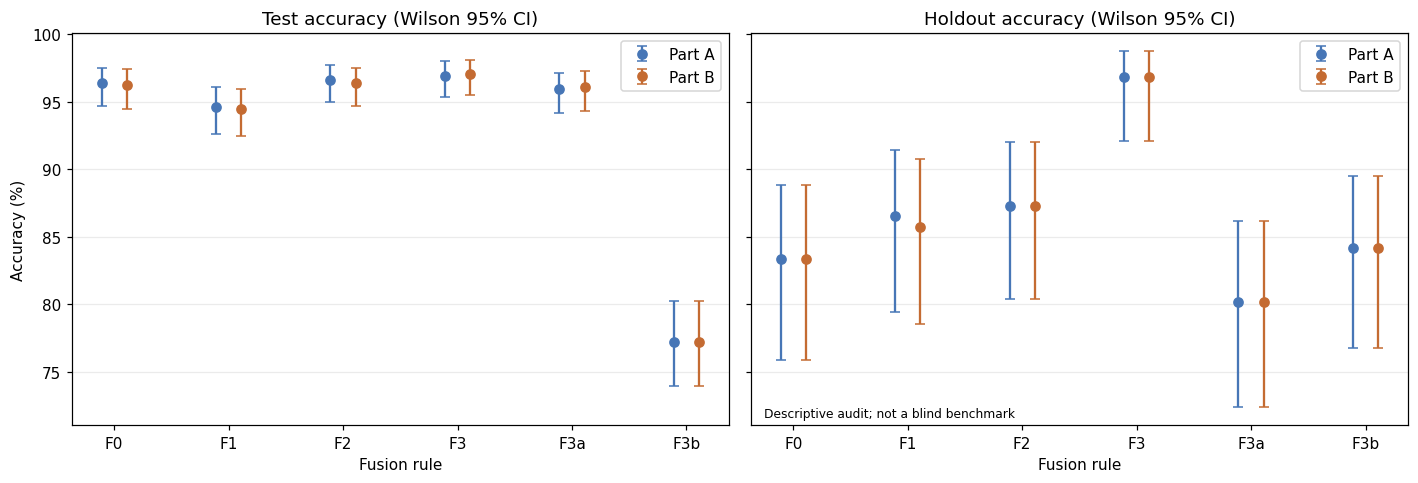

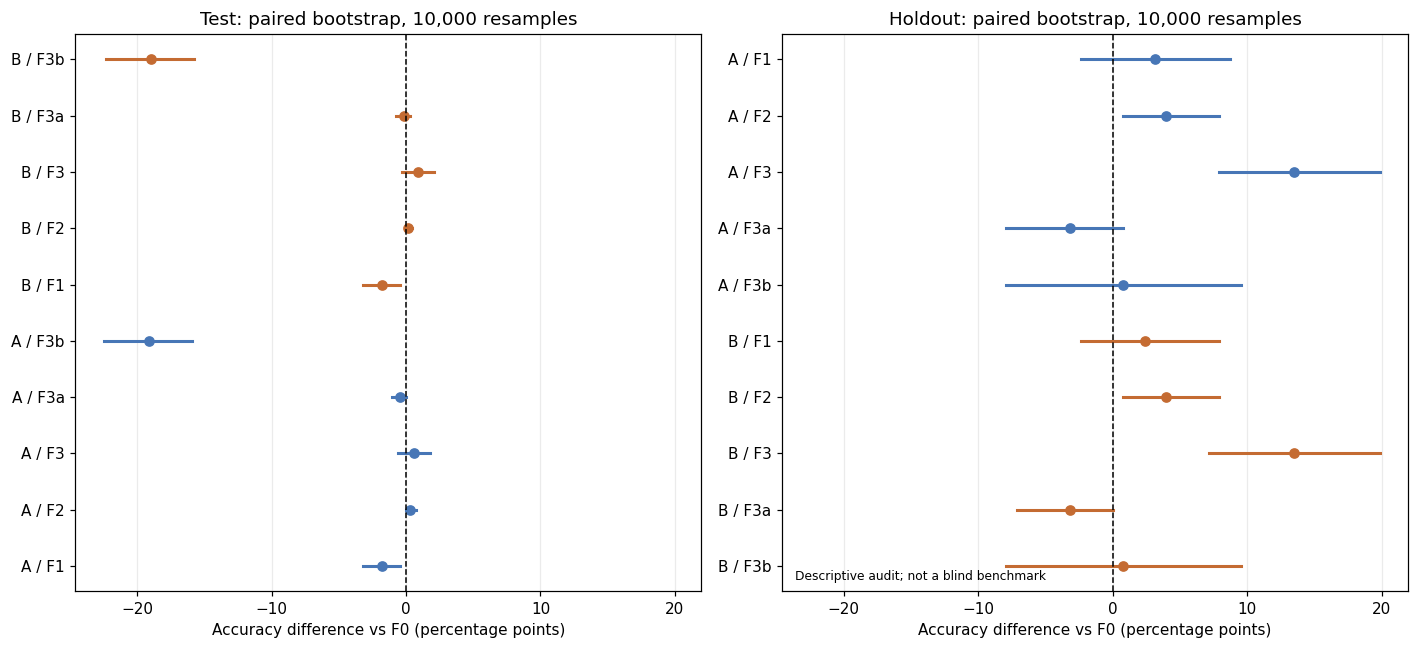

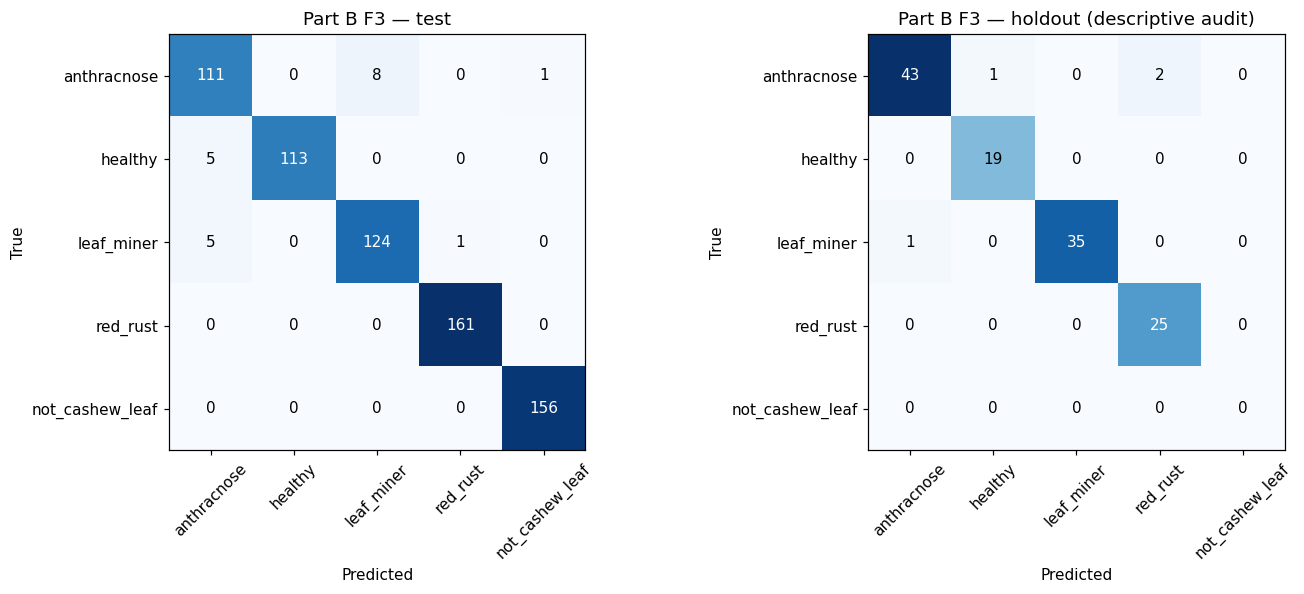

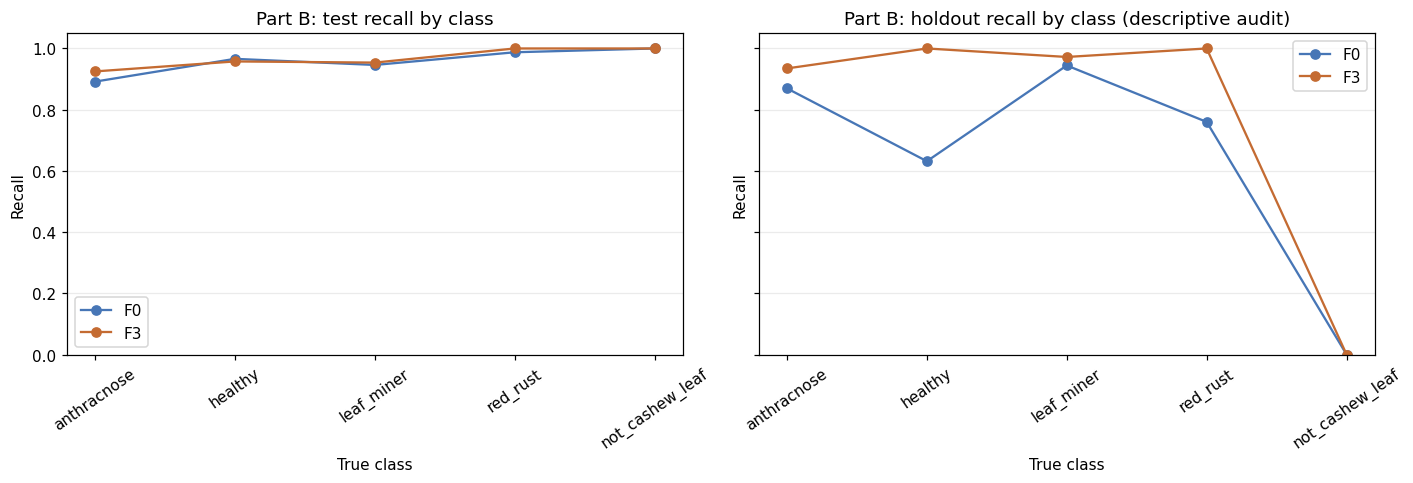

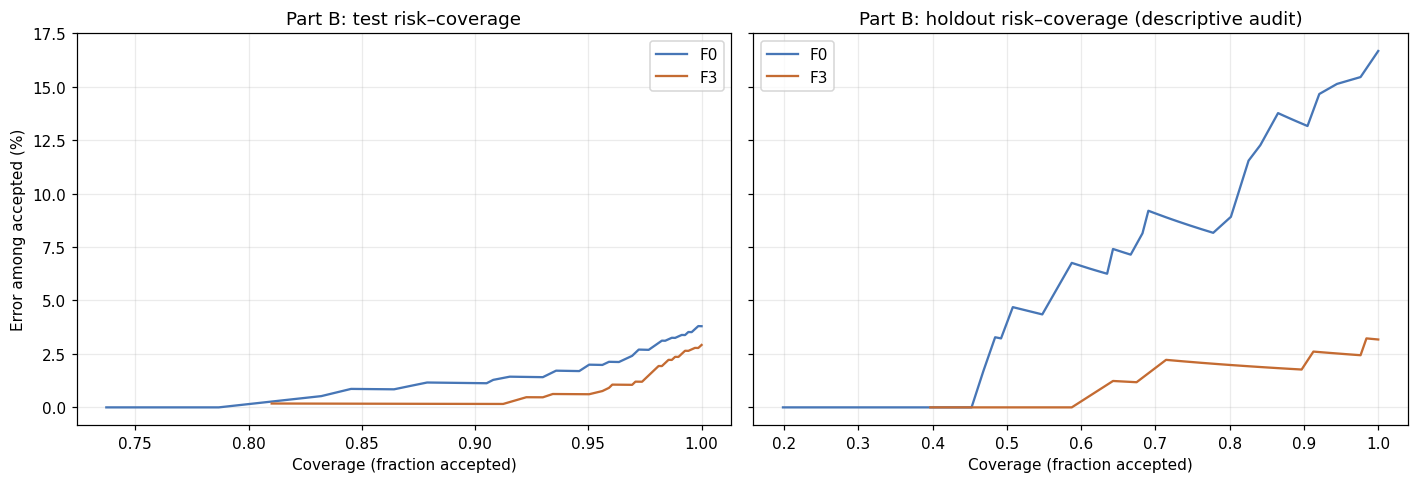

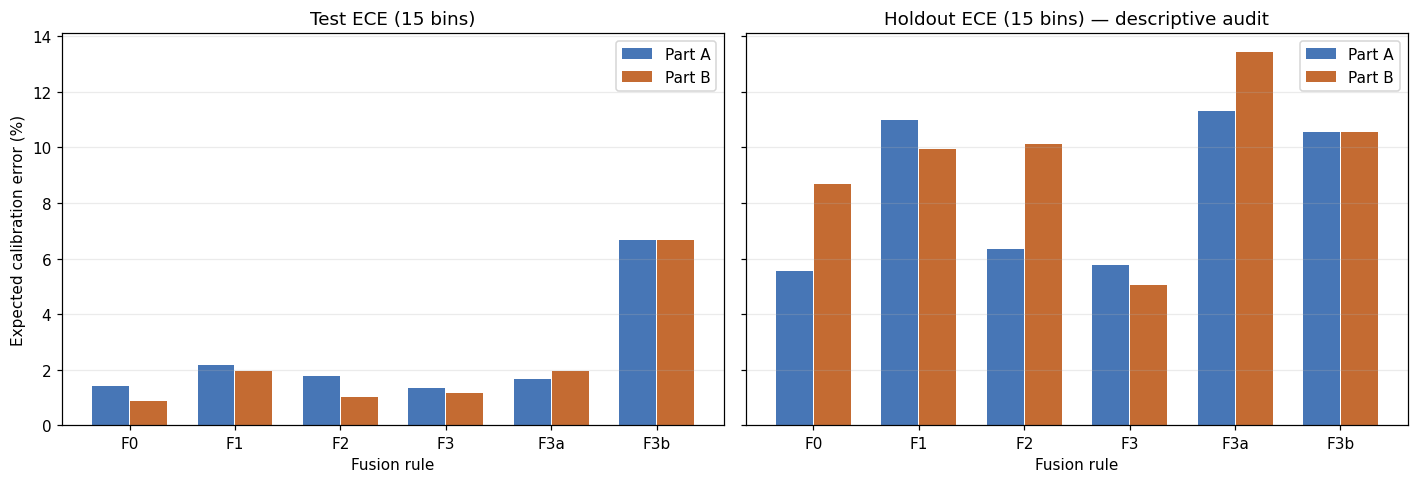

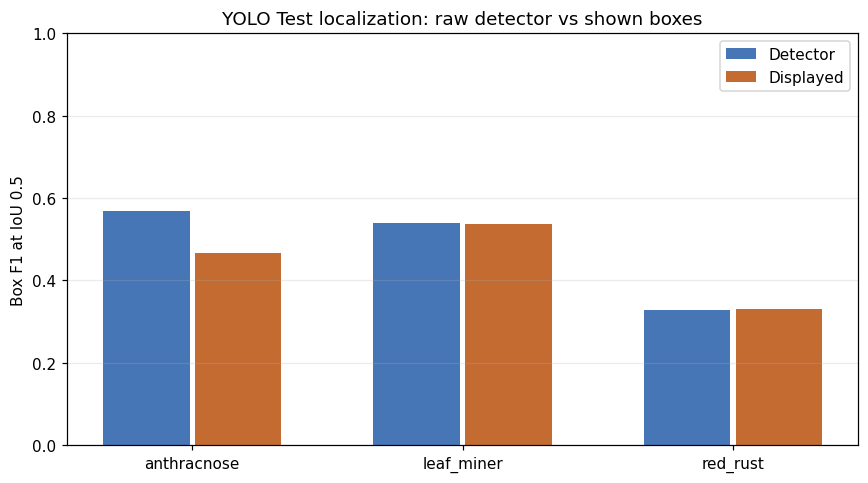

Saved 7 validation figures to /content/training_results/current_dataset/EXP-DENSENET121-YOLO-PIPELINE-032-R1/aggregate/figures
accuracy_wilson.png
paired_bootstrap_vs_f0.png
confusion_selected_rule.png
recall_by_class.png
risk_coverage.png
calibration_ece15.png
localization_f1.png


In [14]:
# EXP-032 — render validation figures from existing aggregate CSVs.
# Run after the evaluation/localization cell, before the ANALYSIS snapshot upload cell.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "OUT_DIR" in globals():
    figure_root = Path(OUT_DIR)
else:
    candidates = [p for p in Path("/content/training_results/current_dataset").glob(
        "EXP-DENSENET121-YOLO-PIPELINE-032*") if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f"Set OUT_DIR to the intended EXP-032 result folder: {candidates}")
    figure_root = candidates[0]
aggregate = figure_root / "aggregate"
if not aggregate.is_dir():
    raise FileNotFoundError(f"No aggregate results in {figure_root}")
figures = aggregate / "figures"
figures.mkdir(exist_ok=True)
classes = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
rules = ["F0", "F1", "F2", "F3", "F3a", "F3b"]

def read_table(name):
    path = aggregate / name
    return pd.read_csv(path) if path.is_file() else pd.DataFrame()

results = pd.concat([read_table("fusion_results_partA.csv"),
                     read_table("fusion_results_partB.csv")], ignore_index=True)
if results.empty:
    raise RuntimeError("No fusion results yet; run Part A or B first")
boot = read_table("paired_bootstrap.csv")
risk = read_table("risk_coverage.csv")
localization = read_table("localization_test.csv")
part = "B" if "B" in set(results.part) else "A"
if "SELECTED_DEFAULT" in globals() and part == "B":
    selected = SELECTED_DEFAULT
elif (aggregate / "exp032_summary.json").is_file() and part == "B":
    selected = json.loads((aggregate / "exp032_summary.json").read_text(
        encoding="utf-8")).get("selected_default_rule") or "F0"
else:
    selected = "F0"
if selected not in rules:
    raise RuntimeError(f"Unknown selected rule: {selected}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 10})
made = []

def save(fig, name):
    fig.tight_layout()
    destination = figures / name
    fig.savefig(destination, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    made.append(destination)

# Wilson intervals describe each accuracy separately; they are not the paired rule comparison.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ("test", "holdout")):
    sub = results[results.split == split]
    for offset, current_part, color in ((-0.11, "A", "#4776b6"),
                                        (0.11, "B", "#c46b32")):
        group = sub[sub.part == current_part].set_index("rule")
        if group.empty:
            continue
        present = [r for r in rules if r in group.index]
        vals = group.loc[present]
        if not {"accuracy", "wilson_low", "wilson_high"}.issubset(vals.columns):
            continue
        x = np.array([rules.index(r) for r in present], dtype=float) + offset
        y = vals.accuracy.to_numpy(dtype=float) * 100
        err = np.vstack((y - vals.wilson_low.to_numpy(dtype=float) * 100,
                         vals.wilson_high.to_numpy(dtype=float) * 100 - y))
        ax.errorbar(x, y, yerr=err, fmt="o", capsize=3, color=color,
                    label=f"Part {current_part}")
    ax.set(title=f"{split.title()} accuracy (Wilson 95% CI)", xlabel="Fusion rule",
           xticks=range(len(rules)), xticklabels=rules)
    ax.grid(axis="y", alpha=.25)
    if split == "holdout":
        ax.text(.02, .02, "Descriptive audit; not a blind benchmark",
                transform=ax.transAxes, fontsize=8)
    ax.legend(loc="best")
axes[0].set_ylabel("Accuracy (%)")
save(fig, "accuracy_wilson.png")

if not boot.empty:
    sub = boot[boot.split.isin(["test", "holdout"])].copy()
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
    for ax, split in zip(axes, ("test", "holdout")):
        view = sub[sub.split == split]
        labels = [f"{p} / {r}" for p in ("A", "B") for r in rules[1:]
                  if ((view.part == p) & (view.rule == r)).any()]
        for y, label in enumerate(labels):
            p, r = label.split(" / ")
            row = view[(view.part == p) & (view.rule == r)].iloc[0]
            lo, mid, hi = [100 * float(row[k]) for k in
                           ("bootstrap_low", "delta_accuracy", "bootstrap_high")]
            ax.plot([lo, hi], [y, y], color="#4776b6" if p == "A" else "#c46b32", lw=2)
            ax.plot(mid, y, "o", color="#4776b6" if p == "A" else "#c46b32")
        ax.axvline(0, color="black", lw=1, ls="--")
        ax.set(yticks=range(len(labels)), yticklabels=labels,
               title=f"{split.title()}: paired bootstrap, 10,000 resamples",
               xlabel="Accuracy difference vs F0 (percentage points)")
        ax.grid(axis="x", alpha=.25)
        if split == "holdout":
            ax.text(.02, .02, "Descriptive audit; not a blind benchmark",
                    transform=ax.transAxes, fontsize=8)
    axes[1].invert_yaxis()
    save(fig, "paired_bootstrap_vs_f0.png")

def confusion(part_name, split, rule):
    path = aggregate / f"confusion_{part_name}_{split}_{rule}.csv"
    return pd.read_csv(path, index_col=0) if path.is_file() else None

matrix_test = confusion(part, "test", selected)
matrix_hold = confusion(part, "holdout", selected)
if matrix_test is not None or matrix_hold is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, split, matrix in zip(axes, ("test", "holdout"),
                                 (matrix_test, matrix_hold)):
        if matrix is None:
            ax.set_axis_off()
            continue
        values = matrix.to_numpy(dtype=int)
        ax.imshow(values, cmap="Blues")
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                ax.text(j, i, str(values[i, j]), ha="center", va="center",
                        color="white" if values[i, j] > values.max() / 2 else "black")
        ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
               yticks=range(len(matrix.index)), yticklabels=matrix.index,
               xlabel="Predicted", ylabel="True",
               title=f"Part {part} {selected} — {split}" +
                     (" (descriptive audit)" if split == "holdout" else ""))
        ax.tick_params(axis="x", labelrotation=45)
    save(fig, "confusion_selected_rule.png")

recall_cols = [f"recall_{name}" for name in classes]
if set(recall_cols).issubset(results.columns):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        subset = results[(results.part == part) & (results.split == split)]
        for rule, color in (("F0", "#4776b6"), (selected, "#c46b32")):
            row = subset[subset.rule == rule]
            if row.empty:
                continue
            ax.plot(classes, row.iloc[0][recall_cols].to_numpy(dtype=float), "o-",
                    label=rule, color=color)
            if rule == selected:
                break
        ax.set(title=f"Part {part}: {split} recall by class" +
                     (" (descriptive audit)" if split == "holdout" else ""),
               ylim=(0, 1.05), ylabel="Recall", xlabel="True class")
        ax.tick_params(axis="x", labelrotation=35)
        ax.grid(axis="y", alpha=.25)
        ax.legend()
    save(fig, "recall_by_class.png")

if not risk.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        for rule, color in (("F0", "#4776b6"), (selected, "#c46b32")):
            view = risk[(risk.part == part) & (risk.split == split) &
                        (risk.rule == rule)].dropna(subset=["coverage", "risk"])
            if not view.empty:
                ax.plot(view.coverage, 100 * view.risk, label=rule, color=color)
            if rule == selected:
                break
        ax.set(title=f"Part {part}: {split} risk–coverage" +
                     (" (descriptive audit)" if split == "holdout" else ""),
               xlabel="Coverage (fraction accepted)")
        ax.grid(alpha=.25)
        ax.legend()
    axes[0].set_ylabel("Error among accepted (%)")
    save(fig, "risk_coverage.png")

if "ece15" in results.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        view = results[results.split == split]
        x = np.arange(len(rules))
        for offset, current_part, color in ((-.18, "A", "#4776b6"),
                                            (.18, "B", "#c46b32")):
            group = view[view.part == current_part].set_index("rule")
            vals = [100 * float(group.loc[r, "ece15"]) if r in group.index
                    else np.nan for r in rules]
            if np.isfinite(vals).any():
                ax.bar(x + offset, vals, width=.35, label=f"Part {current_part}",
                       color=color)
        ax.set(xticks=x, xticklabels=rules, title=f"{split.title()} ECE (15 bins)" +
               (" — descriptive audit" if split == "holdout" else ""),
               xlabel="Fusion rule")
        ax.grid(axis="y", alpha=.25)
        ax.legend()
    axes[0].set_ylabel("Expected calibration error (%)")
    save(fig, "calibration_ece15.png")

if not localization.empty:
    view = localization[localization.subset == "all"].copy()
    if "mode" not in view.columns:
        view["mode"] = "detector_only"
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = np.arange(3)
    for offset, mode, label, color in ((-.17, "detector_only", "Detector", "#4776b6"),
                                       (.17, "fused_display", "Displayed", "#c46b32")):
        vals = []
        for cls in ("anthracnose", "leaf_miner", "red_rust"):
            row = view[(view["class"] == cls) & (view["mode"] == mode)]
            vals.append(float(row.iloc[0].f1_50) if not row.empty else np.nan)
        if np.isfinite(vals).any():
            ax.bar(x + offset, vals, width=.32, label=label, color=color)
    ax.set(xticks=x, xticklabels=["anthracnose", "leaf_miner", "red_rust"],
           ylim=(0, 1), ylabel="Box F1 at IoU 0.5",
           title="YOLO Test localization: raw detector vs shown boxes")
    ax.legend()
    ax.grid(axis="y", alpha=.25)
    save(fig, "localization_f1.png")

note = ("# EXP-032 validation figures\n\n"
        "Generated from aggregate CSVs without fitting or selecting any parameters.\n\n"
        "Wilson intervals describe single-rule accuracy. The paired bootstrap figure "
        "shows the 95% interval of each rule's difference from F0. Holdout figures "
        "are descriptive audits, not blind benchmarks. Localization uses labeled "
        "YOLO Test only; Holdout has no box ground truth. The risk–coverage curves "
        "sweep thresholds for illustration and do not retune the frozen abstention "
        "threshold. The ECE bar chart summarizes calibration error; a reliability diagram "
        "requires per-image calibrated probabilities, which the aggregate tables "
        "do not retain.\n")
(figures / "README.md").write_text(note, encoding="utf-8")
print("Saved", len(made), "validation figures to", figures)
for path in made:
    print(path.name)
